# Mid-Review preliminary experiment

Goal: test whether the speech features our guide listed actually differ between depressed and non-depressed participants in DAIC-WOZ, then train a simple baseline classifier.

Steps:
1. Load transcripts and keep only the participant's speech
2. Timing features from transcripts (words/sec, response latency, pauses, fillers)
3. Voice features from COVAREP (pitch, voice quality)
4. Compare depressed vs. non-depressed (plots + statistical tests)
5. Baseline classifiers: 12 models on the official dev split and with cross-validation, feature-importance ranking, feature-reduction tests (importance pruning, RFE, ANOVA, L1, PCA), and a comparison with the official AVEC 2016 baseline

## Step 1: Load transcripts and keep only the participant's speech

Each interview has a transcript file: one row per spoken utterance, with four columns:

| column | meaning |
|---|---|
| `start_time`, `stop_time` | when the utterance starts and ends, in seconds from the start of the recording |
| `speaker` | `Ellie` (the virtual interviewer) or `Participant` |
| `value` | what was said, written in lowercase |

We only want to analyse the **participant**. Ellie is a computer, so her speech says nothing about the participant's mental state. Worse, her follow-up questions partly depend on how the participant is doing, so using them would leak the answer to the model.

But we keep Ellie's timestamps for later: the gap between Ellie finishing a question and the participant starting to answer is the *response latency* feature (Step 2).

In [1]:
import os
import sys

# Windows fix: put this environment's own DLL folder first on the PATH. If VS Code starts the kernel
# without activating the conda environment, matplotlib otherwise crashes the kernel when drawing plots.
os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]

from pathlib import Path

import pandas as pd

DATA = Path("..") / "DAIC_WOZ"
TRANSCRIPTS = DATA / "transcripts"
SPLITS = DATA / "splits"

print("Transcript files found:", len(list(TRANSCRIPTS.glob("*_TRANSCRIPT.csv"))))

Transcript files found: 189


### 1a. Look at one transcript

The files are *tab*-separated even though they end in `.csv`, so we pass `sep="\t"`.

In [2]:
t = pd.read_csv(TRANSCRIPTS / "300_TRANSCRIPT.csv", sep="\t")
t.head(12)

,start_time,stop_time,speaker,value
0,36.588,39.668,Ellie,hi i'm ellie thanks for coming in today
1,39.888,43.378,Ellie,i was created to talk to people in a safe and ...
2,43.728,48.498,Ellie,think of me as a friend i don't judge i can't ...
3,49.188,52.388,Ellie,i'm here to learn about people and would love ...
4,52.658,58.958,Ellie,i'll ask a few questions to get us started and...
5,60.028,61.378,Ellie,how are you doing today
6,62.328,63.178,Participant,good
7,63.798,64.738,Ellie,that's good
8,65.858,67.528,Ellie,where are you from originally
9,68.978,70.288,Participant,atlanta georgia


In [3]:
# How many rows belong to each speaker in this interview?
t["speaker"].value_counts()

speaker
Ellie          87
Participant    87
Name: count, dtype: int64

### 1b. Clean-up rules

Checking all 189 transcripts turned up three things to handle:

- **A few rows have empty text** (sessions 313, 381, 402, 409, 453, 476). We drop them.
- **Sessions 451, 458 and 480 have no Ellie rows at all**: only the participant was transcribed. Their participant speech is still usable, but response latency can't be computed for them (it will be missing, not zero).
- **One answer is often split across several consecutive participant rows.** That's fine for now. In Step 2 we'll group consecutive rows into one *answer* when measuring response latency.

We also add a `duration` column (`stop_time - start_time`), the length of each utterance in seconds.

In [4]:
def load_transcript(session_id):
    """Full transcript (both speakers) with empty rows removed and a duration column added."""
    t = pd.read_csv(TRANSCRIPTS / f"{session_id}_TRANSCRIPT.csv", sep="\t")
    t = t.dropna(subset=["value"]).reset_index(drop=True)
    t["duration"] = t["stop_time"] - t["start_time"]
    return t


def participant_rows(t):
    """Keep only what the participant said."""
    return t[t["speaker"] == "Participant"].reset_index(drop=True)


p = participant_rows(load_transcript(300))
p.head(10)

,start_time,stop_time,speaker,value,duration
0,62.328,63.178,Participant,good,0.85
1,68.978,70.288,Participant,atlanta georgia,1.31
2,75.028,78.128,Participant,um my parents are from here um,3.10
3,83.808,84.588,Participant,i love it,0.78
4,88.458,89.968,Participant,i like the weather,1.51
5,90.278,93.568,Participant,i like the opportunities,3.29
6,94.738,95.298,Participant,um,0.56
7,96.588,97.278,Participant,yes,0.69
8,102.428,103.268,Participant,um,0.84
9,104.278,105.558,Participant,it took a minute,1.28


### 1c. Attach the labels

The labels live in the `splits/` folder, one file per official split (train / dev / test). The column we need is the **binary label**: `1` = depressed (PHQ-8 score ≥ 10), `0` = not depressed.

The test file names its columns slightly differently (`PHQ_Binary` instead of `PHQ8_Binary`), so we rename them to match before combining.

In [5]:
def load_split(filename, split_name):
    df = pd.read_csv(SPLITS / filename)
    df = df.rename(columns={"PHQ_Binary": "PHQ8_Binary", "PHQ_Score": "PHQ8_Score"})
    df = df[["Participant_ID", "PHQ8_Binary", "PHQ8_Score", "Gender"]]
    df["split"] = split_name
    return df


labels = pd.concat([
    load_split("train_split_Depression_AVEC2017.csv", "train"),
    load_split("dev_split_Depression_AVEC2017.csv", "dev"),
    load_split("full_test_split.csv", "test"),
], ignore_index=True)

print("Participants with labels:", len(labels))
pd.crosstab(labels["split"], labels["PHQ8_Binary"], margins=True)

Participants with labels: 189


PHQ8_Binary,0,1,All
split,,,
dev,23,12,35
test,33,14,47
train,77,30,107
All,133,56,189


### 1d. Run it over all 189 interviews

For each participant, a quick summary: how many utterances they made, and how many minutes they actually spoke. This becomes the dataset slide.

In [6]:
rows = []
for sid in labels["Participant_ID"]:
    t = load_transcript(sid)
    p = participant_rows(t)
    rows.append({
        "Participant_ID": sid,
        "n_utterances": len(p),
        "speech_min": p["duration"].sum() / 60,
        "interview_min": (t["stop_time"].max() - t["start_time"].min()) / 60,
        "has_ellie": (t["speaker"] == "Ellie").any(),
    })

sessions = labels.merge(pd.DataFrame(rows), on="Participant_ID")
sessions.head()

,Participant_ID,PHQ8_Binary,PHQ8_Score,Gender,split,n_utterances,speech_min,interview_min,has_ellie
0,303,0,0,0,train,103,10.715500,15.568333,True
1,304,0,6,0,train,104,6.043333,12.000667,True
2,305,0,7,1,train,288,18.641500,27.519167,True
3,310,0,4,1,train,148,4.764167,13.048750,True
4,312,0,2,1,train,126,5.231667,11.985333,True


In [7]:
# Overall numbers for the dataset slide
sessions[["n_utterances", "speech_min", "interview_min"]].describe().round(1)

,n_utterances,speech_min,interview_min
count,189.0,189.0,189.0
mean,171.3,7.8,15.1
std,75.0,3.9,4.5
min,42.0,1.0,6.0
25%,118.0,4.9,12.0
50%,155.0,7.0,14.4
75%,211.0,9.9,16.8
max,386.0,21.4,31.9


In [8]:
# A first look at the guide's idea: do depressed participants (1) speak less overall?
sessions.groupby("PHQ8_Binary")[["n_utterances", "speech_min"]].median().round(1)

,n_utterances,speech_min
PHQ8_Binary,,
0,153.0,7.0
1,158.5,7.2


### Before moving to Step 2, make sure you can explain:

- Why we drop Ellie's text but keep her timestamps.
- What `PHQ8_Binary` means and where the cutoff of 10 comes from.
- Why the data is imbalanced (about 30% depressed), and why that means accuracy alone would be misleading.
- What the last table shows. It's only a median, with no statistical test yet; Step 4 adds that.

## Step 2: Timing features from the transcripts

Goal: turn each interview into **one row of numbers** describing *how* the participant talks: how fast, how quickly they respond, how much they pause, how often they hesitate.

| Feature | How it's measured | Why it might signal depression |
|---|---|---|
| `words_per_sec` | total words ÷ total speaking time | slowed thinking/movement → slower speech |
| `median_latency_s` | median gap between Ellie finishing and the participant starting | slower to respond |
| `pauses_per_min`, `mean_pause_s`, `pause_pct` | gaps *inside* an answer | more hesitation |
| `fillers_per_100w` | "um", "uh", "mm", "hmm" per 100 words | hesitation, word-finding difficulty |
| `laughter_per_min`, `sigh_per_min` | transcribed `<laughter>` / `<sigh>` events | less laughter, more sighing |
| `words_per_answer` | average answer length | shorter, less elaborated answers |

We build this in small pieces (2a–2e), checking each piece on one interview (session 300) before running it on all 189.

### 2a. Group rows into answers

One answer is often split over several consecutive participant rows: the transcriber starts a new row whenever the person pauses. So we define an **answer** as a run of consecutive `Participant` rows with no Ellie row in between.

How the code does it, using a pandas tool called `shift(1)`: it gives the value from the **previous row**. A row *starts a new answer* if it's a participant row and the previous row was not. Counting those starts with a running total (`cumsum`) numbers the answers 1, 2, 3, …

In [9]:
def add_answer_ids(t):
    """Add an answer_id column: consecutive participant rows share one id; Ellie rows get NaN."""
    t = t.copy()
    is_participant = t["speaker"] == "Participant"
    previous_is_participant = is_participant.shift(1, fill_value=False)
    starts_new_answer = is_participant & ~previous_is_participant
    t["answer_id"] = starts_new_answer.cumsum().where(is_participant)
    return t


t300 = add_answer_ids(load_transcript(300))
t300[["start_time", "stop_time", "speaker", "value", "answer_id"]].iloc[5:20]

,start_time,stop_time,speaker,value,answer_id
5,60.028,61.378,Ellie,how are you doing today,NaN
6,62.328,63.178,Participant,good,1.0
7,63.798,64.738,Ellie,that's good,NaN
8,65.858,67.528,Ellie,where are you from originally,NaN
9,68.978,70.288,Participant,atlanta georgia,2.0
10,70.978,71.868,Ellie,really,NaN
11,72.788,74.198,Ellie,why'd you move to l_a,NaN
12,75.028,78.128,Participant,um my parents are from here um,3.0
13,82.218,83.578,Ellie,how do you like l_a,NaN
14,83.808,84.588,Participant,i love it,4.0


Check the output: rows with the same `answer_id` are one answer; Ellie's rows show `NaN` (no answer id).

### 2b. Counting words, fillers and non-verbal events

The transcribers marked non-speech events in angle brackets, for example `<laughter>`, `<sigh>` or `<clears throat>`. They also used brackets for **cut-off word fragments** like `<th>` or `<wa>`, where someone stopped mid-word. A few laughs are written `[laughter]` with square brackets.

Rules:
- **Words** = everything except bracketed tags. Fillers ("um", "uh") **do** count as words, because they are spoken sounds.
- **Laughter** = `<laughter>` or `[laughter]`; **sigh** = `<sigh>`.
- Names and places were anonymised (`scrubbed_entry`), and acronyms are spelled with underscores (`l_a` = "LA"). Each counts as one word, which is fine.

`re` is Python's pattern-matching ("regular expression") module. `<[^>]*>` means "a `<`, then anything that isn't `>`, then `>`", i.e. one angle-bracket tag.

In [10]:
import re

TAG = re.compile(r"<[^>]*>|\[[^\]]*\]")   # <anything> or [anything]
FILLERS = {"um", "uh", "mm", "hmm"}


def words_in(text):
    """Spoken words in one utterance: bracketed tags removed, fillers kept."""
    return TAG.sub(" ", text).split()


example = "um <laughter> i like the weather <sigh> uh yeah"
print(words_in(example))
print("fillers:", sum(w in FILLERS for w in words_in(example)))
print("laughter:", len(re.findall(r"<laughter>|\[laughter\]", example)))

['um', 'i', 'like', 'the', 'weather', 'uh', 'yeah']
fillers: 2
laughter: 1


### 2c. Response latency

For every answer that comes straight after an Ellie row:

**latency = participant's `start_time` − Ellie's `stop_time`**

Two details:
- About 9% of answers **start before Ellie's row has ended** (people talk over her), which gives a negative number. A negative wait makes no sense, so we set those to **0** ("answered immediately").
- We summarise each person by the **median** latency, not the mean. A few very long gaps (someone thinking hard about one difficult question) would drag a mean up; the median ignores those extremes.

Note: Ellie sometimes says a short "mhm" in the middle of a participant's answer. That splits the answer in two, and the gap after the "mhm" also counts as a latency. This is a limitation to mention if asked; the median keeps its effect small.

In [11]:
def response_latencies(t):
    """Seconds from the end of an Ellie row to the start of the participant answer right after it."""
    previous_speaker = t["speaker"].shift(1)
    previous_stop = t["stop_time"].shift(1)
    answer_starts = (t["speaker"] == "Participant") & (previous_speaker == "Ellie")
    latency = t.loc[answer_starts, "start_time"] - previous_stop[answer_starts]
    return latency.clip(lower=0)


lat300 = response_latencies(t300)
print("answers after Ellie:", len(lat300))
print("median latency (s):", round(lat300.median(), 2))
lat300.describe().round(2)

answers after Ellie: 58
median latency (s): 1.22


count    58.00
mean      1.62
std       1.78
min       0.00
25%       0.60
50%       1.22
75%       1.76
max       8.29
dtype: float64

### 2d. Pauses inside answers

Inside one answer, the gap between the end of one row and the start of the next is a **pause**: the person stopped and then carried on. Across all transcripts every such gap is at least ~0.2 s, so we count every gap as a pause.

- `pauses_per_min` = number of pauses ÷ minutes of speech
- `mean_pause_s` = average pause length
- `pause_pct` = pause time ÷ (pause time + speaking time) inside answers, as a percentage

Limitation: these timestamps were set by human transcribers, so they're approximate. Later in the project, Parselmouth will measure pauses precisely from the audio itself.

In [12]:
def within_answer_pauses(t):
    """Length of every gap between consecutive rows of the same answer."""
    same_answer = t["answer_id"].notna() & (t["answer_id"] == t["answer_id"].shift(1))
    gaps = t.loc[same_answer, "start_time"] - t["stop_time"].shift(1)[same_answer]
    return gaps


pauses300 = within_answer_pauses(t300)
print("pauses:", len(pauses300), "| mean length (s):", round(pauses300.mean(), 2))

pauses: 29 | mean length (s): 0.87


### 2e. Put it together: one row of timing features per participant

`timing_features(session_id)` runs 2a–2d on one interview and returns a dictionary of the 9 features. Then we run it on all 189 interviews.

**Sessions 451, 458 and 480 have no Ellie rows**, so we can't tell where one answer ends and the next begins. The whole interview would look like one giant answer, and the gaps where Ellie was actually speaking would be miscounted as pauses. For those three sessions, latency, the pause features and `words_per_answer` are set to **missing** (`NaN`), not zero. Their words/sec, filler, laughter and sigh rates are still valid. Step 5 decides how to fill in the missing values.

In [13]:
import numpy as np


def timing_features(session_id):
    t = add_answer_ids(load_transcript(session_id))
    p = participant_rows(t)

    words = [words_in(v) for v in p["value"]]
    n_words = sum(len(w) for w in words)
    n_fillers = sum(word in FILLERS for w in words for word in w)
    all_text = " ".join(p["value"])
    n_laughter = len(re.findall(r"<laughter>|\[laughter\]", all_text))
    n_sigh = len(re.findall(r"<sigh>", all_text))

    speech_s = p["duration"].sum()
    speech_min = speech_s / 60
    latencies = response_latencies(t)
    pauses = within_answer_pauses(t)
    n_answers = t["answer_id"].nunique()

    if not (t["speaker"] == "Ellie").any():
        # No Ellie rows: answers can't be separated, so these features are unknown.
        latencies = pauses = pd.Series(dtype=float)
        n_answers = np.nan

    return {
        "Participant_ID": session_id,
        "words_per_sec": n_words / speech_s,
        "median_latency_s": latencies.median() if len(latencies) else np.nan,
        "pauses_per_min": len(pauses) / speech_min if len(pauses) else np.nan,
        "mean_pause_s": pauses.mean() if len(pauses) else np.nan,
        "pause_pct": 100 * pauses.sum() / (pauses.sum() + speech_s) if len(pauses) else np.nan,
        "fillers_per_100w": 100 * n_fillers / n_words,
        "laughter_per_min": n_laughter / speech_min,
        "sigh_per_min": n_sigh / speech_min,
        "words_per_answer": n_words / n_answers,
    }


timing_features(300)

{'Participant_ID': 300,
 'words_per_sec': 2.2534668721109403,
 'median_latency_s': 1.2150000000000176,
 'pauses_per_min': 11.171032357473038,
 'mean_pause_s': 0.873448275862067,
 'pause_pct': 13.987520017670745,
 'fillers_per_100w': 8.831908831908832,
 'laughter_per_min': 0.3852080123266565,
 'sigh_per_min': 0.0,
 'words_per_answer': 6.051724137931035}

In [14]:
timing = pd.DataFrame([timing_features(sid) for sid in sessions["Participant_ID"]])
features = sessions.merge(timing, on="Participant_ID")

TIMING_COLS = [c for c in timing.columns if c != "Participant_ID"]
features[TIMING_COLS].describe().round(2)

,words_per_sec,median_latency_s,pauses_per_min,mean_pause_s,pause_pct,fillers_per_100w,laughter_per_min,sigh_per_min,words_per_answer
count,189.00,186.00,186.00,186.00,186.00,189.00,189.00,189.00,186.00
mean,3.09,0.96,14.30,1.16,20.91,5.26,1.17,0.48,26.02
std,0.43,0.44,5.49,0.37,8.69,2.78,1.22,0.71,16.06
min,1.98,0.11,0.64,0.51,1.59,0.38,0.00,0.00,3.17
25%,2.79,0.66,10.58,0.89,14.15,3.28,0.32,0.00,14.70
50%,3.08,0.91,14.16,1.10,20.46,4.89,0.80,0.21,22.49
75%,3.37,1.18,17.81,1.36,26.38,6.51,1.52,0.70,31.82
max,4.23,2.92,34.98,2.66,47.50,16.06,6.51,4.68,93.26


In [15]:
# Missing values per feature (expect 3 in latency, pause and words-per-answer columns: sessions 451, 458, 480)
features[TIMING_COLS].isna().sum()

words_per_sec       0
median_latency_s    3
pauses_per_min      3
mean_pause_s        3
pause_pct           3
fillers_per_100w    0
laughter_per_min    0
sigh_per_min        0
words_per_answer    3
dtype: int64

### 2f. Save the result

We save the table to a CSV file so Step 5 (and your partner, building the classifiers in parallel) can load it without re-running everything.

In [16]:
OUT = Path("..") / "data" / "mid_review"
OUT.mkdir(parents=True, exist_ok=True)
features.to_csv(OUT / "timing_features.csv", index=False)
print("Saved", features.shape, "to", OUT / "timing_features.csv")

Saved (189, 18) to ..\data\mid_review\timing_features.csv


### Before moving to Step 3, make sure you can explain:

- What an **answer** is, and why one answer can span several rows.
- How response latency is measured, why negatives become 0, and why we use the **median**.
- The difference between a **pause** (inside an answer) and a **latency** (before an answer).
- Why fillers count as words but `<laughter>` doesn't.
- Why missing latency is `NaN` and not 0.
- One limitation: transcript timestamps are approximate.

Don't compare depressed vs. non-depressed yet. That's Step 4, done properly on the training set with statistical tests.

## Step 3: Voice features from COVAREP

Step 2 measured *timing*. Step 3 measures the **voice itself**: pitch and voice quality.

The dataset ships these as COVAREP files, already computed from the audio:
- **One row every 10 ms**, so 100 rows per second. Row 6,233 is the moment 62.33 s into the recording.
- **74 columns, no header row.** The names come from the dataset documentation.
- It covers the **whole recording**: it has no idea who is speaking. Only the transcript knows that.

The columns we use:

| Column | Meaning | Plain English |
|---|---|---|
| `F0` | pitch in Hz | only meaningful when `VUV` = 1 |
| `VUV` | voiced (1) / unvoiced (0) | are the vocal folds vibrating in this 10 ms? |
| `NAQ` | normalised amplitude quotient | how abruptly the vocal folds close. Higher = relaxed/breathy, lower = tense |
| `QOQ` | quasi-open quotient | fraction of each cycle the folds stay open. Higher = breathier |
| `H1H2` | 1st harmonic minus 2nd harmonic (dB) | higher = breathier |
| `peakSlope` | how fast energy drops at high frequencies | steeper (more negative) = breathier, weaker voice |
| `Rd` | one overall "voice shape" number | low = tense, high = lax/breathy |

NAQ, QOQ and peakSlope matter in particular: the team who built DAIC-WOZ (Scherer and colleagues) found they differ in depressed speakers.

**Skipped on purpose:**
- `PSP` and `MDQ` (similar breathiness measures; fewer features is safer with only 107 training people)
- `creak`: empty in every session
- the 63 spectral/phase columns (MCEP, HMPDM, HMPDD): too many numbers for this small dataset, and hard to interpret

### 3a. Load one COVAREP file

We read only the first 10 columns (`usecols`). The full files are 9.6 GB in total, and we don't need the rest.

In [17]:
import numpy as np

COVAREP = DATA / "covarep"
FORMANT = DATA / "formant"
COVAREP_COLS = ["F0", "VUV", "NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd", "Rd_conf"]
FRAMES_PER_SEC = 100


def load_covarep(session_id):
    c = pd.read_csv(COVAREP / f"{session_id}_COVAREP.csv", header=None, usecols=range(len(COVAREP_COLS)))
    c.columns = COVAREP_COLS
    return c


c300 = load_covarep(300)
print("frames:", len(c300), "=", len(c300) / FRAMES_PER_SEC, "seconds")
c300.iloc[6228:6240]   # around the participant's first word, "good" (transcript says 62.33 s)

frames: 64851 = 648.51 seconds


,F0,VUV,NAQ,QOQ,H1H2,PSP,MDQ,peakSlope,Rd,Rd_conf
6228,120.0,1,0.194180,0.34637,5.9151,0.15779,0.128810,-0.37105,1.71090,0.46994
6229,120.0,1,0.235440,0.41903,5.5830,0.23186,0.136520,-0.37632,2.08200,0.43413
6230,120.0,1,0.183790,0.35395,6.1905,0.14341,0.109700,-0.37819,2.09450,0.47408
6231,120.0,1,0.253230,0.53520,16.9520,0.40977,0.130180,-0.37354,1.73530,0.57474
6232,120.0,1,0.215540,0.40150,8.9809,0.23224,0.096378,-0.37297,1.83850,0.57476
6233,120.5,1,0.217860,0.42031,8.3323,0.30187,0.108890,-0.36833,1.89110,0.56404
6234,121.0,1,0.211410,0.41233,7.1819,0.20966,0.129900,-0.36254,1.83810,0.50425
6235,169.5,1,0.144890,0.32740,-4.7080,0.16047,0.115430,-0.39424,1.66390,0.44909
6236,218.0,1,0.060429,0.21400,-19.8610,0.14670,0.083217,-0.42220,2.01560,0.41455
6237,218.5,1,0.101610,0.39084,0.0000,0.14779,0.134830,-0.42447,1.47440,0.49701


Look at the output:
- `VUV` = 1 and `F0` holds a pitch value: someone is voicing. (Voicing actually starts about 0.6 s *before* the transcript's 62.33 s, which is the "timestamps are approximate" limitation from Step 2, visible right here.)
- Frame 6237 has `H1H2` = 0.0000 exactly. That's a **failed measurement**, explained in 3c.

### 3b. Label every frame with who is speaking, and check the alignment

For each transcript row, the frames from `start_time × 100` to `stop_time × 100` get that row's speaker. Frames not covered by any row are labelled `none`.

Then a **sanity check**: if transcript and COVAREP are aligned correctly, frames labelled `Participant` should be mostly voiced, and `none` frames mostly not.

In [18]:
def frame_speaker(t, n_frames):
    """For each 10 ms frame: 'Participant', 'Ellie' or 'none' (nobody, according to the transcript)."""
    who = np.full(n_frames, "none", dtype=object)
    for _, row in t.iterrows():
        first = int(row["start_time"] * FRAMES_PER_SEC)
        last = min(int(row["stop_time"] * FRAMES_PER_SEC), n_frames)
        who[first:last] = row["speaker"]
    return who


who300 = frame_speaker(load_transcript(300), len(c300))
print("Fraction of frames that are voiced, by who the transcript says is speaking:")
c300.groupby(who300)["VUV"].mean().round(2)

Fraction of frames that are voiced, by who the transcript says is speaking:


Ellie          0.48
Participant    0.71
none           0.29
Name: VUV, dtype: float64

Participant frames are ~71% voiced and `none` frames ~29%, so the alignment works.

But notice: **Ellie's frames are also ~48% voiced.** Her voice, played through a speaker in the room, leaks into the participant's microphone. If we didn't filter by the transcript, we'd be measuring Ellie's computer voice as if it were the participant's. This is the second reason (after Step 1) why we keep only the participant's frames.

### 3c. Keep only voiced participant frames

This is the most important detail in Step 3. In unvoiced frames (silence, or sounds like "s" and "f"), the vocal folds aren't vibrating, so there *is* no pitch. But COVAREP **still writes a number** in the `F0` column: a meaningless guess from noise, often near the top of its search range. The voice-quality columns are equally meaningless there.

Including those frames corrupts the measurements. The output below shows it: average pitch is pushed **up**, and pitch variability (our "monotone" measure) is badly inflated.

In [19]:
participant = who300 == "Participant"
voiced = participant & (c300["VUV"] == 1).to_numpy()

print("participant frames:", participant.sum(), "| voiced:", voiced.sum(),
      f"({100 * voiced.sum() / participant.sum():.0f}%)")
print("mean F0, ALL participant frames:   ", round(c300.loc[participant, "F0"].mean(), 1), "Hz  <- wrong, includes unvoiced guesses")
print("mean F0, VOICED participant frames:", round(c300.loc[voiced, "F0"].mean(), 1), "Hz")
print("F0 spread, ALL frames:   ", round(c300.loc[participant, "F0"].std(), 1), "Hz  <- wrong")
print("F0 spread, VOICED frames:", round(c300.loc[voiced, "F0"].std(), 1), "Hz")

participant frames: 15576 | voiced: 11098 (71%)
mean F0, ALL participant frames:    151.4 Hz  <- wrong, includes unvoiced guesses
mean F0, VOICED participant frames: 142.9 Hz
F0 spread, ALL frames:    44.7 Hz  <- wrong
F0 spread, VOICED frames: 33.7 Hz


**One more clean-up:** in about 2–4% of voiced frames, `NAQ`, `QOQ` and `H1H2` are exactly 0. A real voice can't produce exactly 0 here; it means COVAREP **failed to measure** that frame. We turn those zeros into `NaN` (missing) so they're ignored, rather than dragging the average down.

### 3d. Pitch on the semitone scale

Women's voices are roughly twice as high as men's. On the Hz scale, a man and a woman with *equally lively* intonation show very different spreads:
- man moving between 100 and 200 Hz → spread of 100 Hz
- woman moving between 200 and 400 Hz → spread of 200 Hz

**Semitones** measure pitch as *ratios*, like a musical scale. Both of those are exactly 12 semitones (one octave). So pitch variability in semitones compares people fairly regardless of gender. eGeMAPS uses semitones for the same reason.

Formula: `semitones = 12 × log2(F0 / 100)`. The reference of 100 Hz doesn't matter for spread measures.

Three pitch features:
- `f0_median_hz`: typical pitch (still in Hz; this one *will* differ by gender, keep that in mind in Step 4)
- `f0_sd_st`: pitch variability in semitones. This is the **"monotone voice"** measure.
- `f0_range_st`: pitch range, from the 5th to the 95th percentile, in semitones. Using percentiles instead of min/max ignores occasional pitch-tracking errors.

In [20]:
def semitones(f0_hz):
    return 12 * np.log2(f0_hz / 100)


st300 = semitones(c300.loc[voiced, "F0"])
print("pitch variability (semitones):", round(st300.std(), 2))
print("pitch range 5th-95th percentile (semitones):", round(st300.quantile(0.95) - st300.quantile(0.05), 2))

pitch variability (semitones): 3.69
pitch range 5th-95th percentile (semitones): 11.31


### 3e. Everything for one participant

`covarep_features(session_id)` combines 3a–3d and returns 16 features:

| Group | Features |
|---|---|
| Voicing | `voiced_pct`: voiced frames as % of the participant's speaking frames |
| Pitch | `f0_median_hz`, `f0_sd_st`, `f0_range_st` |
| Voice quality | average (`_mean`) and variability (`_sd`) of NAQ, QOQ, H1H2, peakSlope, Rd |
| Formants (vowel space) | `f1_sd_hz`, `f2_sd_hz`: how widely the first two formants move |

**About the formants:** the FORMANT files hold the mouth/throat resonances F1–F5, also at 100 rows/sec, aligned with COVAREP. F1 and F2 define which vowel is being said. People who move their tongue and jaw less produce vowels that sound more alike, so their F1/F2 vary less. That's the **"reduced vowel space"** effect (Scherer et al.; the paper is in `documents/`). Formants also differ by gender (shorter vocal tract = higher formants), so these two get the same gender caution as `f0_median_hz`.

In [21]:
FAILS_AS_ZERO = ["NAQ", "QOQ", "H1H2"]
QUALITY_COLS = ["NAQ", "QOQ", "H1H2", "peakSlope", "Rd"]


def covarep_features(session_id):
    c = load_covarep(session_id)
    f = pd.read_csv(FORMANT / f"{session_id}_FORMANT.csv", header=None, usecols=[0, 1])
    f.columns = ["F1", "F2"]
    n = min(len(c), len(f))   # the two files can differ by a frame or so
    c, f = c.iloc[:n], f.iloc[:n]

    who = frame_speaker(load_transcript(session_id), n)
    participant = who == "Participant"
    voiced = participant & (c["VUV"] == 1).to_numpy()
    v = c[voiced]
    st = semitones(v["F0"])

    feats = {
        "Participant_ID": session_id,
        "voiced_pct": 100 * voiced.sum() / participant.sum(),
        "f0_median_hz": v["F0"].median(),
        "f0_sd_st": st.std(),
        "f0_range_st": st.quantile(0.95) - st.quantile(0.05),
    }
    for col in QUALITY_COLS:
        x = v[col].replace(0, np.nan) if col in FAILS_AS_ZERO else v[col]
        feats[f"{col.lower()}_mean"] = x.mean()
        feats[f"{col.lower()}_sd"] = x.std()
    feats["f1_sd_hz"] = f.loc[voiced, "F1"].std()
    feats["f2_sd_hz"] = f.loc[voiced, "F2"].std()
    return feats


covarep_features(300)

{'Participant_ID': 300,
 'voiced_pct': 71.25064201335388,
 'f0_median_hz': 129.0,
 'f0_sd_st': 3.690292904862247,
 'f0_range_st': 11.311465307069103,
 'naq_mean': 0.1239930653450621,
 'naq_sd': 0.0538298626448041,
 'qoq_mean': 0.39131691525056683,
 'qoq_sd': 0.1477738152116503,
 'h1h2_mean': 3.1752092967184478,
 'h1h2_sd': 7.787196514965673,
 'peakslope_mean': -0.38070860695620834,
 'peakslope_sd': 0.07418598776729741,
 'rd_mean': 1.3914807505856912,
 'rd_sd': 0.6804937002176743,
 'f1_sd_hz': 253.1717684827785,
 'f2_sd_hz': 420.2704200519932}

### 3f. Run on all 189 participants

This reads 189 COVAREP files and takes about a minute. The progress counter prints every 20 participants.

In [22]:
voice_rows = []
for i, sid in enumerate(features["Participant_ID"], start=1):
    voice_rows.append(covarep_features(sid))
    if i % 20 == 0 or i == len(features):
        print(f"{i} / {len(features)}")

voice = pd.DataFrame(voice_rows)
VOICE_COLS = [c for c in voice.columns if c != "Participant_ID"]
all_features = features.merge(voice, on="Participant_ID")
all_features[VOICE_COLS].describe().round(2)

20 / 189


40 / 189


60 / 189


80 / 189


100 / 189


120 / 189


140 / 189


160 / 189


180 / 189


189 / 189


,voiced_pct,f0_median_hz,f0_sd_st,f0_range_st,naq_mean,naq_sd,qoq_mean,qoq_sd,h1h2_mean,h1h2_sd,peakslope_mean,peakslope_sd,rd_mean,rd_sd,f1_sd_hz,f2_sd_hz
count,189.00,189.00,189.00,189.00,189.00,189.00,189.00,189.00,189.00,189.00,189.00,189.00,189.00,189.00,189.00,189.00
mean,61.47,136.77,3.07,9.65,0.10,0.04,0.36,0.14,3.34,5.47,-0.39,0.06,1.30,0.47,182.82,424.19
std,8.38,39.52,0.65,2.75,0.02,0.01,0.06,0.04,2.97,0.87,0.04,0.01,0.24,0.11,20.51,53.80
min,27.51,75.50,1.17,3.50,0.02,0.03,0.14,0.09,-2.96,3.41,-0.49,0.04,0.68,0.31,116.40,295.05
25%,56.81,100.00,2.63,7.79,0.08,0.04,0.32,0.12,1.18,4.84,-0.42,0.05,1.12,0.40,169.64,378.50
50%,62.90,129.00,3.09,9.46,0.10,0.04,0.36,0.13,3.50,5.43,-0.39,0.06,1.32,0.44,182.37,425.47
75%,67.04,176.00,3.47,10.96,0.11,0.05,0.40,0.15,5.25,6.03,-0.37,0.07,1.45,0.49,195.71,464.94
max,78.01,216.00,5.20,19.71,0.16,0.08,0.51,0.48,10.18,8.39,-0.23,0.10,2.04,0.91,253.17,557.64


In [23]:
# Missing values in the new voice features (expect none)
all_features[VOICE_COLS].isna().sum().sum()

0

In [24]:
FEATURE_COLS = TIMING_COLS + VOICE_COLS
print(len(TIMING_COLS), "timing +", len(VOICE_COLS), "voice =", len(FEATURE_COLS), "features per participant")

all_features.to_csv(OUT / "all_features.csv", index=False)
print("Saved", all_features.shape, "to", OUT / "all_features.csv")

9 timing + 16 voice = 25 features per participant
Saved (189, 34) to ..\data\mid_review\all_features.csv


### Before moving to Step 4, make sure you can explain:

- What one row of a COVAREP file represents, and how row number ↔ time works (100 rows per second).
- Why we must label frames with the speaker. Two reasons: Ellie's speech isn't the participant's, **and** her voice leaks into the microphone.
- Why we keep only **voiced** frames: COVAREP still writes pitch guesses in unvoiced frames, which inflate pitch and its variability (the "wrong" numbers in 3c).
- Why zeros in NAQ/QOQ/H1H2 are treated as missing.
- Why pitch variability is measured in **semitones**, and which features still depend on gender (`f0_median_hz`, `f1_sd_hz`, `f2_sd_hz`).
- What NAQ, QOQ and peakSlope roughly measure (breathy vs. tense voice), and why they're relevant to depression.

## Step 4: Compare depressed vs. non-depressed

For **each feature separately**: do depressed participants tend to have different values? This step *describes* the data; Step 5 does the predicting.

**Which participants:** the main analysis uses **all 189**, labelled as *descriptive*. The training-set-only version (107 people) is shown next to it as a stability check.

This is safe only because of one firm rule: **Step 5 never uses Step 4's results to choose features.** The main benchmark uses all 25 features. The feature-pruning test in Step 5 ranks features with its own method, using only train+dev people and only the training part of each cross-validation fold. If we used Step 4 (which includes the dev and test people) to *pick* features, information about the people we evaluate on would leak into the evaluation.

Tools used (explained in detail in the chat walkthrough):
- **Box plots**, to see each feature's distribution in both groups
- **Effect size**: over every pair of (depressed, non-depressed) people, (wins − losses) ÷ pairs. Runs from −1 to +1; 0 = no difference; positive = depressed tend to be *higher*. Rough guide: 0.15 small, 0.33 medium, 0.47 large.
- **Mann-Whitney U test** → p-value: how likely a difference this big is by pure chance
- **Benjamini-Hochberg correction**, because we test 25 features at once
- **Gender-normalisation**, to remove gender as a confounder

### 4a. The gender problem, in numbers

In the label files, `Gender` is coded 0/1. The pitch values confirm **0 = female, 1 = male** (median pitch about 178 Hz vs. 101 Hz). We add readable columns `sex` and `group` for tables and plots.

In [25]:
from scipy.stats import mannwhitneyu, false_discovery_control
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# seaborn 0.13 triggers a harmless deprecation notice in matplotlib 3.11 on every box plot; hide it.
warnings.filterwarnings("ignore", message="vert: bool was deprecated")

all_features["sex"] = all_features["Gender"].map({0: "female", 1: "male"})
all_features["group"] = all_features["PHQ8_Binary"].map({0: "not depressed", 1: "depressed"})
GROUP_ORDER = ["not depressed", "depressed"]

print("Share of each sex that is depressed:")
pd.crosstab(all_features["sex"], all_features["group"], normalize="index").round(2)

Share of each sex that is depressed:


group,depressed,not depressed
sex,,
female,0.36,0.64
male,0.25,0.75


In [26]:
# Women's voices are higher and breathier than men's, for biological reasons unrelated to depression.
all_features.groupby("sex")[["f0_median_hz", "h1h2_mean"]].median().round(1)

,f0_median_hz,h1h2_mean
sex,,
female,177.5,4.8
male,101.0,1.3


A larger share of women than men is depressed (36% vs. 25%), **and** women have higher, breathier voices. So the depressed group contains proportionally more women, and its pitch is higher on average **even if depression doesn't change pitch at all**. Gender is a **confounder**.

### 4b. One feature by hand: response latency

Before running all 25 features in a loop, here's one test written out so every number is visible.

`mannwhitneyu(a, b)` returns **U**: the number of (depressed, non-depressed) pairs where the depressed person has the higher value (ties count as half). Dividing by the number of pairs gives the "win rate", and the effect size is `2 × win rate − 1`.

In [27]:
dep = all_features["PHQ8_Binary"] == 1
a = all_features.loc[dep, "median_latency_s"].dropna()     # depressed
b = all_features.loc[~dep, "median_latency_s"].dropna()    # not depressed

u, p = mannwhitneyu(a, b, alternative="two-sided")
pairs = len(a) * len(b)
print(f"pairs compared: {len(a)} x {len(b)} = {pairs}")
print(f"U = {u:.0f}  ->  depressed person has the longer latency in {u / pairs:.0%} of pairs")
print(f"effect size = {2 * u / pairs - 1:+.2f}")
print(f"p-value = {p:.4f}")

pairs compared: 56 x 130 = 7280
U = 4602  ->  depressed person has the longer latency in 63% of pairs
effect size = +0.26
p-value = 0.0043


### 4c. All 25 features: raw comparison (no gender adjustment)

`compare_groups` runs the same test on every feature and adds the Benjamini-Hochberg corrected p-value (`p_corrected`). Only results with `p_corrected` below 0.05 should be called "significant".

In [28]:
def compare_groups(df, cols):
    """Mann-Whitney U test per feature, depressed vs. not. Sorted by p-value."""
    dep = df["PHQ8_Binary"] == 1
    rows = []
    for col in cols:
        a = df.loc[dep, col].dropna()
        b = df.loc[~dep, col].dropna()
        u, p = mannwhitneyu(a, b, alternative="two-sided")
        rows.append({
            "feature": col,
            "median_depressed": a.median(),
            "median_not": b.median(),
            "effect": 2 * u / (len(a) * len(b)) - 1,
            "p": p,
        })
    table = pd.DataFrame(rows)
    table["p_corrected"] = false_discovery_control(table["p"])
    return table.sort_values("p").reset_index(drop=True)


raw_table = compare_groups(all_features, FEATURE_COLS)
raw_table.round(3)

,feature,median_depressed,median_not,effect,p,p_corrected
0,median_latency_s,1.024,0.834,0.264,0.004,0.104
1,qoq_sd,0.140,0.127,0.244,0.008,0.104
2,h1h2_mean,4.068,3.132,0.191,0.039,0.211
3,naq_sd,0.046,0.044,0.184,0.046,0.211
4,fillers_per_100w,4.481,5.041,-0.176,0.056,0.211
5,rd_sd,0.447,0.432,0.175,0.059,0.211
6,mean_pause_s,1.159,1.064,0.173,0.061,0.211
7,voiced_pct,62.498,63.313,-0.165,0.074,0.211
8,f1_sd_hz,187.696,180.947,0.163,0.078,0.211
9,h1h2_sd,5.653,5.341,0.159,0.084,0.211


In this raw table, `h1h2_mean` is near the top (p ≈ 0.04) and `f0_median_hz` comes a little lower (p ≈ 0.10): depressed participants *seem* to have breathier, higher-pitched voices. From 4a we know that's at least partly because the depressed group has more women. Note also that `median_latency_s` is top of the list but does **not** survive the correction here (`p_corrected` ≈ 0.10). Keep an eye on what happens to it in 4d.

### 4d. Gender-normalised comparison (the main result)

Each feature is rescaled **within each sex**:

> normalised value = (person's value − average for their sex) ÷ spread for their sex

After this, a value of +1.0 means "one spread above the average *for people of your own sex*". The gender difference is gone, and only individual differences remain.

(Here the averages come from all 189 people, which is fine for a descriptive analysis. In Step 5, any rescaling will use **training-set** averages only.)

The table keeps the **raw medians** (in real units such as seconds), so it's readable, but the effect size and p-values come from the gender-normalised values.

In [29]:
def gender_normalise(df, cols):
    """Rescale each feature within each sex: (value - sex mean) / sex std."""
    out = df.copy()
    for col in cols:
        by_sex = df.groupby("sex")[col]
        out[col] = (df[col] - by_sex.transform("mean")) / by_sex.transform("std")
    return out


norm_table = compare_groups(gender_normalise(all_features, FEATURE_COLS), FEATURE_COLS)
main_table = norm_table[["feature", "effect", "p", "p_corrected"]].merge(
    raw_table[["feature", "median_depressed", "median_not"]], on="feature")
main_table = main_table[["feature", "median_depressed", "median_not", "effect", "p", "p_corrected"]]
main_table.round(3)

,feature,median_depressed,median_not,effect,p,p_corrected
0,median_latency_s,1.024,0.834,0.317,0.001,0.016
1,qoq_sd,0.140,0.127,0.229,0.013,0.138
2,mean_pause_s,1.159,1.064,0.222,0.017,0.138
3,voiced_pct,62.498,63.313,-0.192,0.037,0.234
4,rd_sd,0.447,0.432,0.169,0.068,0.338
5,fillers_per_100w,4.481,5.041,-0.154,0.095,0.380
6,naq_sd,0.046,0.044,0.149,0.106,0.380
7,pause_pct,20.910,20.129,0.138,0.136,0.390
8,f1_sd_hz,187.696,180.947,0.136,0.140,0.390
9,h1h2_mean,4.068,3.132,0.109,0.239,0.597


**Notice what happened to latency between 4c and 4d:** its effect grew from +0.26 to +0.32 and it became significant. That's because men in this dataset respond *slower* than women (median about 1.00 s vs 0.82 s), while the depressed group has proportionally more women. So gender was **hiding** part of the latency difference. A confounder can hide a real effect, not only create a fake one.

### 4e. Stability check: training set only

The same gender-normalised analysis, but on the 107 training participants only (30 depressed). Fewer people means less power to detect a real difference, so expect weaker p-values. The useful question is whether the **effect sizes point the same way**.

In [30]:
train_only = all_features[all_features["split"] == "train"]
train_table = compare_groups(gender_normalise(train_only, FEATURE_COLS), FEATURE_COLS)

stability = main_table[["feature", "effect", "p_corrected"]].merge(
    train_table[["feature", "effect", "p_corrected"]], on="feature", suffixes=("_all189", "_train"))
stability.head(10).round(3)

,feature,effect_all189,p_corrected_all189,effect_train,p_corrected_train
0,median_latency_s,0.317,0.016,0.173,0.946
1,qoq_sd,0.229,0.138,0.184,0.946
2,mean_pause_s,0.222,0.138,0.107,0.946
3,voiced_pct,-0.192,0.234,-0.093,0.946
4,rd_sd,0.169,0.338,0.115,0.946
5,fillers_per_100w,-0.154,0.380,-0.023,0.977
6,naq_sd,0.149,0.380,0.139,0.946
7,pause_pct,0.138,0.390,-0.068,0.946
8,f1_sd_hz,0.136,0.390,0.166,0.946
9,h1h2_mean,0.109,0.597,0.128,0.946


### 4f. Plots for the slides

Box plots of the **4 strongest features** from the gender-normalised analysis. The plots show the *raw* values (real units), and each title gives the effect size and corrected p-value from 4d. Every dot is one participant.

Figures are saved to `results/mid_review/` at high resolution, ready to paste into slides.

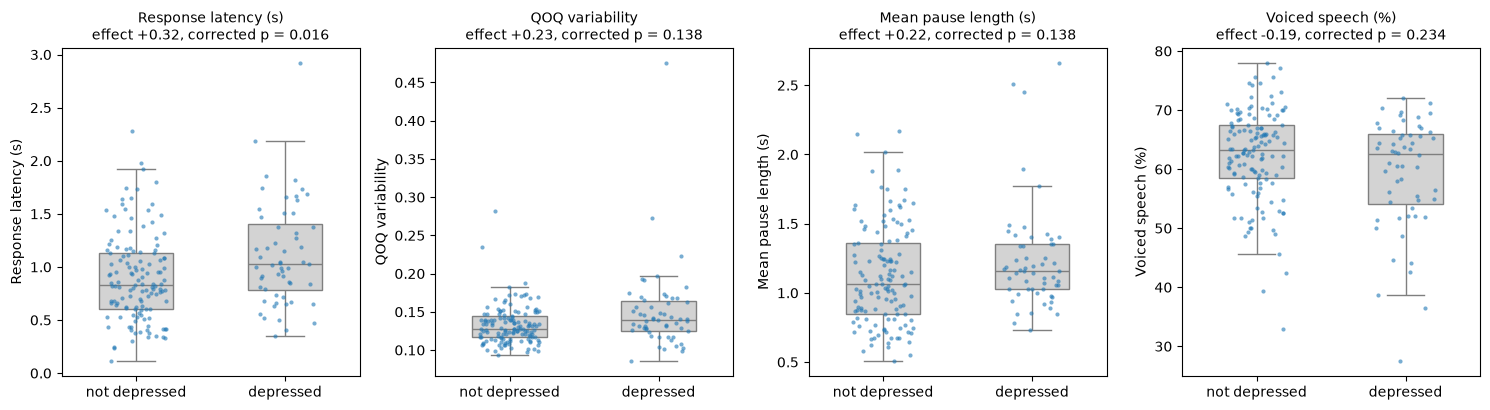

In [31]:
RESULTS = Path("..") / "results" / "mid_review"
RESULTS.mkdir(parents=True, exist_ok=True)

LABELS = {
    "words_per_sec": "Words per second", "median_latency_s": "Response latency (s)",
    "pauses_per_min": "Pauses per minute", "mean_pause_s": "Mean pause length (s)",
    "pause_pct": "Time paused (%)", "fillers_per_100w": "Fillers per 100 words",
    "laughter_per_min": "Laughter per minute", "sigh_per_min": "Sighs per minute",
    "words_per_answer": "Words per answer", "voiced_pct": "Voiced speech (%)",
    "f0_median_hz": "Median pitch (Hz)", "f0_sd_st": "Pitch variability (semitones)",
    "f0_range_st": "Pitch range (semitones)", "naq_mean": "NAQ (mean)", "naq_sd": "NAQ variability",
    "qoq_mean": "QOQ (mean)", "qoq_sd": "QOQ variability", "h1h2_mean": "H1-H2 (mean, dB)",
    "h1h2_sd": "H1-H2 variability", "peakslope_mean": "Peak slope (mean)",
    "peakslope_sd": "Peak slope variability", "rd_mean": "Rd (mean)", "rd_sd": "Rd variability",
    "f1_sd_hz": "F1 spread (Hz)", "f2_sd_hz": "F2 spread (Hz)",
}

fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, (_, row) in zip(axes, main_table.head(4).iterrows()):
    col = row["feature"]
    sns.boxplot(data=all_features, x="group", y=col, order=GROUP_ORDER, ax=ax,
                showfliers=False, color="lightgrey", width=0.5)
    sns.stripplot(data=all_features, x="group", y=col, order=GROUP_ORDER, ax=ax,
                  size=3, alpha=0.6, jitter=0.2)
    ax.set_title(f"{LABELS[col]}\neffect {row['effect']:+.2f}, corrected p = {row['p_corrected']:.3f}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel(LABELS[col])
fig.tight_layout()
fig.savefig(RESULTS / "top_features_boxplots.png", dpi=200)
plt.show()

And the **confounding plot**: median pitch split by sex *and* depression. Within each sex, the two groups look similar. The big difference is between the sexes. Useful for the Q&A ("how did you handle gender?").

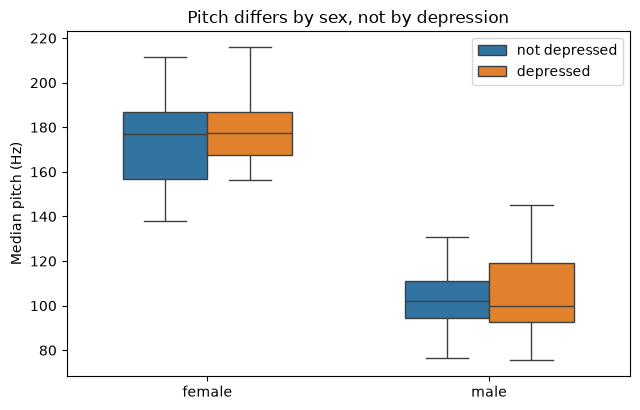

In [32]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.boxplot(data=all_features, x="sex", y="f0_median_hz", hue="group", hue_order=GROUP_ORDER,
            ax=ax, showfliers=False, width=0.6)
ax.set_xlabel("")
ax.set_ylabel("Median pitch (Hz)")
ax.set_title("Pitch differs by sex, not by depression")
ax.legend(title="")
fig.tight_layout()
fig.savefig(RESULTS / "pitch_gender_confound.png", dpi=200)
plt.show()

In [33]:
main_table.to_csv(RESULTS / "feature_comparison.csv", index=False)
stability.to_csv(RESULTS / "feature_comparison_stability.csv", index=False)
print("Saved tables and figures to", RESULTS)

Saved tables and figures to ..\results\mid_review


### What Step 4 tells us (for the slides)

Read your tables and check that this summary matches them:

1. **Response latency is the clearest finding.** Depressed participants take longer to start answering, and it is the only feature that stays significant after the multiple-testing correction. It's a medium-sized effect, consistent with the slowed thinking and movement seen in depression.
2. **The raw pitch and breathiness differences are gender effects.** They shrink or disappear after gender-normalisation. This is evidence from our own data for Objective 3 (stopping the model from relying on gender).
3. **Every single feature is weak on its own.** Even latency's groups overlap heavily, and on the training set alone (4e) nothing reaches significance. So no single number can diagnose depression. This motivates **combining features** (Step 5) and modelling **how speech changes across the interview** (the GNN), instead of whole-interview averages.

### Before moving to Step 5, make sure you can explain:

- How to read a box plot, and what the dots are.
- What the effect size means in plain words (e.g. "+0.32 → the depressed person is higher in about 66% of pairs").
- What a p-value is (the "shuffle the labels" idea), and why we need the multiple-testing correction for 25 features.
- What a **confounder** is, using the gender/pitch example, and how gender-normalisation removes it.
- Why using all 189 people here doesn't contaminate Step 5 (Step 5 never uses Step 4's results to pick features).
- Why the train-only results are weaker (fewer people, less power), and why we show them anyway.

## Step 5: Baseline classifiers

Step 4 asked whether each feature *differs* between the groups. Step 5 asks the practical question: **given a new person's 25 features, can a model predict whether they're depressed?**

The rules, decided before looking at any results:
- **Train on `train`** (107 people), **evaluate on `dev`** (35 people). This matches how the AVEC 2016/2017 papers report results, so our numbers are comparable.
- **`test` stays untouched** until the End-Review.
- **The main benchmark uses all 25 features**, with no selection based on Step 4. Discarding features is tested separately (5j–5k.3), with the feature ranking learned inside each training fold.
- **Model settings are fixed in advance and never tuned on dev**, and **every model is reported**, not just the best. Most models use library defaults; a few have simple limits set beforehand because the training set is tiny (tree depth 3–5, a smaller learning rate for XGBoost/LightGBM). Trying many settings and keeping the winner would turn the 35 dev people into a second training set.

### 5a. Training and dev sets

`X` means "the features" and `y` means "the label" (1 = depressed). This is standard machine-learning notation.

In [34]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             ConfusionMatrixDisplay)

train = all_features[all_features["split"] == "train"]
dev = all_features[all_features["split"] == "dev"]

for name, part in [("train", train), ("dev", dev)]:
    print(f"{name}: {len(part)} people, {part['PHQ8_Binary'].sum()} depressed")

train: 107 people, 30 depressed
dev: 35 people, 12 depressed


### 5b. Preparation steps, bundled into a pipeline

Before a model sees the data, two preparation steps are needed:

1. **Fill in missing values** (`SimpleImputer`). Sessions 451, 458 and 480 have no latency or pause values. Each gap gets the **median of the training set** for that feature.
2. **Put all features on the same scale** (`StandardScaler`). Words/sec is around 3, but F2 spread is around 400. Some models would treat bigger numbers as more important just because they're bigger. Each feature is rescaled to average 0, spread 1.

**The key rule:** the medians, averages and spreads are learned from the **training set only**, then applied unchanged to dev. Learning them from dev too would leak information about the dev people into training.

A scikit-learn **pipeline** chains the steps together: fill gaps → rescale → model. When you call `.fit()` on training data, every step learns from training data only. When you call `.predict()` on dev data, every step just applies what it learned. That makes leakage hard to do by accident.

In [35]:
def make_pipeline_for(model):
    """Fill missing values -> rescale -> model. Every step learns from training data only."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)


make_pipeline_for(LogisticRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive est

### 5c. The 12 models

Per mentor guidance, we expand the baseline suite from 3 to **12 models**, covering linear, margin-based, bagging, boosting, instance-based, probabilistic and neural approaches, plus a Dummy baseline that marks chance level:

| Family | Model | How it works / why include it |
|---|---|---|
| **Chance floor** | **Dummy** | Always predicts "not depressed" (the majority class). Shows why accuracy is misleading under imbalance. |
| **Linear** | **Logistic Regression** | Standard linear model. Its standardised coefficients show which way each feature pushes the prediction. |
| **Margin / kernel** | **SVM (RBF kernel)** | Finds the widest-margin boundary between the classes after the RBF kernel bends the feature space. A classic choice in speech-depression papers. |
| **Bagging** | **Random Forest** | 300 decision trees, each trained on a random resample of the people and random subsets of features. Captures non-linear interactions. |
| **Bagging** | **Extra Trees** | Like Random Forest, but split thresholds are also chosen at random, which reduces variance on small datasets. |
| **Single tree** | **Decision Tree** | One readable rule-based tree, depth capped at 5 to limit overfitting. |
| **Boosting** | **Gradient Boosting** | Trees added one at a time, each correcting the previous ones' errors. The standard scikit-learn boosting baseline. |
| **Boosting** | **AdaBoost** | Re-weights misclassified people after each round, using depth-2 trees. |
| **Boosting** | **XGBoost** | Regularised gradient-boosted trees, widely used and fast. |
| **Boosting** | **LightGBM** | Fast histogram-based gradient boosting that grows trees leaf by leaf. |
| **Instance-based** | **k-Nearest Neighbours** | Predicts from the 5 most similar people in the standardised feature space; closer neighbours count more. |
| **Probabilistic** | **Gaussian Naive Bayes** | Assumes features are independent within each class. Fast and works on tiny data, though its probabilities are often poorly calibrated. |
| **Neural network** | **MLP** | Small neural network: one hidden layer of 64 units, ReLU, Adam optimiser, early stopping on 10% of the training data. A bridge to deep learning. |

**Class imbalance (77 not depressed vs. 30 depressed in train):** 7 of the 12 models are told to weight depressed people more heavily: Logistic Regression, SVM, Random Forest, Extra Trees, Decision Tree and LightGBM (`class_weight="balanced"`), and XGBoost (`scale_pos_weight` = 77 ÷ 30 ≈ 2.57). The other 5 (Gradient Boosting, AdaBoost, k-NN, Naive Bayes, MLP) have no such option in scikit-learn and are trained **unweighted**, so they tend to predict "not depressed" more often. Keep this in mind when comparing their depressed recall.

In [36]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Class imbalance ratio from the training set (77 non-depressed / 30 depressed = 2.567)
POS_WEIGHT = (train["PHQ8_Binary"] == 0).sum() / max((train["PHQ8_Binary"] == 1).sum(), 1)

def make_models(seed=0):
    """Fresh, unfitted copies of the 12 models + Dummy baseline."""
    return {
        "Dummy (chance floor)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=seed),
        "SVM (RBF Kernel)": SVC(class_weight="balanced", random_state=seed),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=seed),
        "Extra Trees": ExtraTreesClassifier(n_estimators=300, class_weight="balanced", random_state=seed),
        "Decision Tree": DecisionTreeClassifier(class_weight="balanced", max_depth=5, random_state=seed),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=seed),
        "AdaBoost": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=50, random_state=seed),
        "XGBoost": XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05,
                                 scale_pos_weight=POS_WEIGHT, eval_metric="logloss",
                                 random_state=seed, verbosity=0),
        "LightGBM": LGBMClassifier(n_estimators=100, max_depth=3, learning_rate=0.05,
                                  class_weight="balanced", random_state=seed, verbose=-1),
        "k-NN": KNeighborsClassifier(n_neighbors=5, weights="distance"),
        "Gaussian Naive Bayes": GaussianNB(),
        "MLP (Neural Net)": MLPClassifier(hidden_layer_sizes=(64,), max_iter=400, early_stopping=True, random_state=seed)
    }

print(f"Models initialised: {len(make_models()) - 1} classifiers + Dummy baseline")

Models initialised: 12 classifiers + Dummy baseline


### 5d. Measuring performance: metrics and inference time

To match speech-depression research (e.g. the AVEC challenges and the IEEE TAFFC survey), we report more than accuracy:

1. **UAR (Unweighted Average Recall, also called balanced accuracy)**: $\text{UAR} = \frac{1}{2}(\text{Recall}_{depressed} + \text{Recall}_{control})$. The main metric in speech-depression papers, because it isn't inflated by class imbalance. Chance level = 0.50.
2. **Macro-F1**: $\frac{1}{2}(F1_{depressed} + F1_{control})$, the F1 score averaged equally over both classes.
3. **F1-Depressed**: balance of precision and recall for the depressed group. The number AVEC papers report, so we can compare directly.
4. **F1-Control**: the same for the non-depressed group.
5. **Precision (depressed)**: of the people flagged as depressed, what fraction really are.
6. **Recall / sensitivity (depressed)**: of the depressed people, what fraction were caught.
7. **Specificity (recall of controls)**: of the non-depressed people, what fraction were correctly cleared.
8. **ROC-AUC**: how well the model's scores rank depressed above non-depressed people, across all possible decision thresholds. 0.50 = chance.
9. **Accuracy**: reported only to show why it misleads. On dev, 23 of 35 people (65.7%) are not depressed, so a dummy that always says "not depressed" scores 65.7% accuracy while catching nobody.
10. **Inference time (ms per person)**: time to predict the 35 dev people in one batch, divided by 35, on this laptop's CPU. It covers only the model's prediction, not feature extraction. A first, rough indicator for Phase 8 (edge deployment); see 5l.

In [37]:
from sklearn.metrics import precision_score, roc_auc_score
import time

def compute_metrics(y_true, y_pred, y_scores=None, latency_ms=0.0):
    """Computes the complete evaluation metrics suite."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    
    auc = np.nan
    if y_scores is not None:
        try:
            auc = roc_auc_score(y_true, y_scores)
        except Exception:
            auc = np.nan
            
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "UAR": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_depressed": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1_not": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
        "precision_depressed": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall_depressed": recall_score(y_true, y_pred, pos_label=1, zero_division=0),  # Sensitivity
        "recall_not": recall_score(y_true, y_pred, pos_label=0, zero_division=0),        # Specificity
        "roc_auc": auc,
        "latency_ms": latency_ms
    }


def run_on_dev(cols, seeds=range(5)):
    """Train all 12 models + Dummy on `train` (N=107), score on `dev` (N=35), averaged over seeds."""
    rows = []
    for seed in seeds:
        for name, model in make_models(seed).items():
            pipe = make_pipeline_for(model).fit(train[cols], train["PHQ8_Binary"])
            
            # Measure inference latency on dev set
            t0 = time.perf_counter()
            preds = pipe.predict(dev[cols])
            t1 = time.perf_counter()
            lat_ms = ((t1 - t0) / len(dev)) * 1000.0
            
            # Extract prediction scores for ROC-AUC
            y_scores = None
            if hasattr(pipe, "predict_proba"):
                try:
                    y_scores = pipe.predict_proba(dev[cols])[:, 1]
                except Exception:
                    pass
            elif hasattr(pipe, "decision_function"):
                try:
                    y_scores = pipe.decision_function(dev[cols])
                except Exception:
                    pass
                    
            metrics = compute_metrics(dev["PHQ8_Binary"], preds, y_scores, lat_ms)
            rows.append({"model": name, "seed": seed, **metrics})
    return pd.DataFrame(rows)


### 5e. Results on the official dev split (all 12 models, 25 features)

We train all 12 models on `train` (107 people) and evaluate on `dev` (35 people), averaging over 5 random seeds. The seed only changes results for models with randomness (e.g. Random Forest, MLP); for the others, all 5 runs are identical.

In [38]:
dev_runs = run_on_dev(FEATURE_COLS)
dev_table = dev_runs.drop(columns="seed").groupby("model", sort=False).mean()
dev_table = dev_table.sort_values(by="UAR", ascending=False)
print("=== Official Dev Set Results (Sorted by UAR) ===")
dev_table[["accuracy", "UAR", "macro_f1", "f1_depressed", "recall_depressed", "recall_not", "roc_auc", "latency_ms"]].round(3)


=== Official Dev Set Results (Sorted by UAR) ===


,accuracy,UAR,macro_f1,f1_depressed,recall_depressed,recall_not,roc_auc,latency_ms
model,,,,,,,,
Gaussian Naive Bayes,0.686,0.661,0.658,0.560,0.583,0.739,0.641,0.043
LightGBM,0.657,0.580,0.580,0.400,0.333,0.826,0.554,0.092
MLP (Neural Net),0.594,0.560,0.510,0.399,0.450,0.670,0.589,0.063
AdaBoost,0.657,0.556,0.543,0.314,0.233,0.878,0.575,0.154
Logistic Regression,0.543,0.553,0.533,0.467,0.583,0.522,0.569,0.040
Random Forest,0.617,0.537,0.534,0.337,0.283,0.791,0.590,0.386
SVM (RBF Kernel),0.600,0.536,0.536,0.364,0.333,0.739,0.525,0.036
XGBoost,0.600,0.536,0.536,0.364,0.333,0.739,0.583,0.091
Extra Trees,0.657,0.520,0.464,0.143,0.083,0.957,0.516,0.388


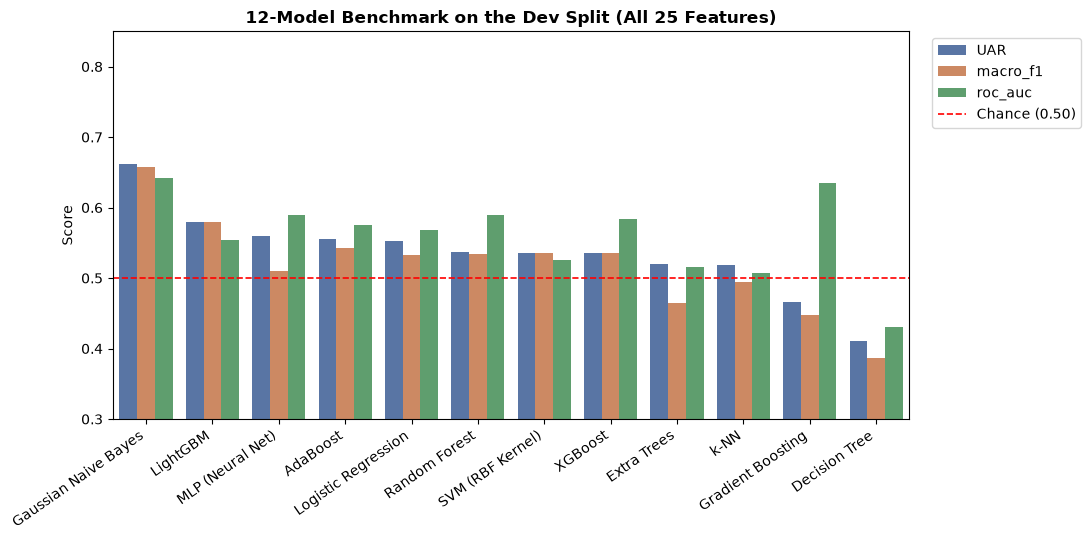

In [39]:
# Plot the 12-model benchmark on dev
fig, ax = plt.subplots(figsize=(11, 5.5))
bench_plot = dev_table.drop(index=["Dummy (chance floor)"], errors="ignore").reset_index()
bench_plot = bench_plot.melt(id_vars="model", value_vars=["UAR", "macro_f1", "roc_auc"], var_name="Metric", value_name="Score")
sns.barplot(data=bench_plot, x="model", y="Score", hue="Metric", palette="deep", ax=ax)
ax.axhline(0.5, color="red", linestyle="--", linewidth=1.2, label="Chance (0.50)")
ax.set_ylim(0.30, 0.85)
ax.tick_params(axis="x", rotation=35)
plt.setp(ax.get_xticklabels(), ha="right")
ax.set_title("12-Model Benchmark on the Dev Split (All 25 Features)", fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(RESULTS / "expanded_10models_dev.png", dpi=200)
plt.show()

### 5f. Confusion matrices: the accuracy trap, visibly

Every prediction falls into one of four boxes (the **confusion matrix**):

| | predicted *not depressed* | predicted *depressed* |
|---|---|---|
| **actually not depressed** | correct | false alarm |
| **actually depressed** | **missed** | correct |

Side by side on the 35 dev people: the dummy, logistic regression (the simplest real model), and Gaussian Naive Bayes (the best dev UAR in 5e).

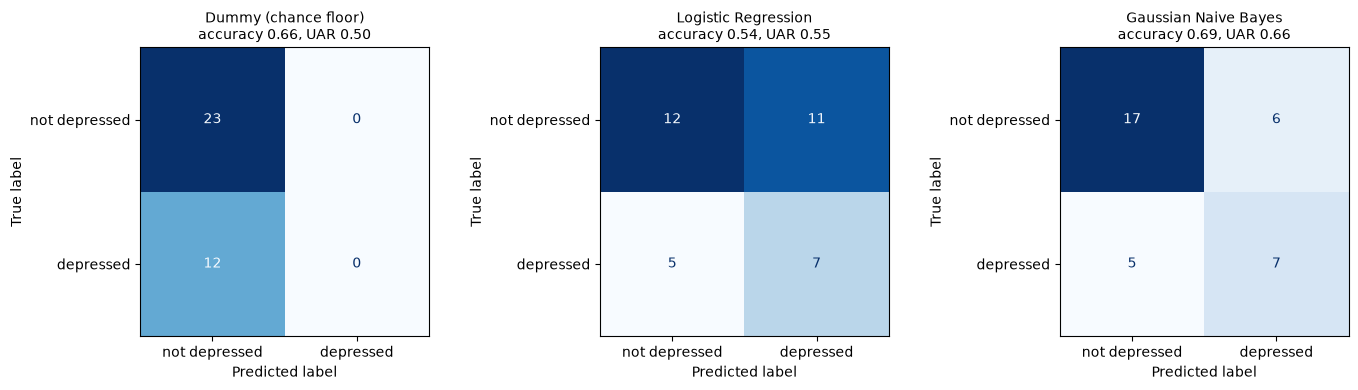

In [40]:
CLASS_NAMES = ["not depressed", "depressed"]
CM_MODELS = ["Dummy (chance floor)", "Logistic Regression", "Gaussian Naive Bayes"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, CM_MODELS):
    pipe = make_pipeline_for(make_models(seed=0)[name]).fit(train[FEATURE_COLS], train["PHQ8_Binary"])
    pred = pipe.predict(dev[FEATURE_COLS])
    ConfusionMatrixDisplay.from_predictions(dev["PHQ8_Binary"], pred, display_labels=CLASS_NAMES,
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\naccuracy {accuracy_score(dev['PHQ8_Binary'], pred):.2f}, "
                 f"UAR {balanced_accuracy_score(dev['PHQ8_Binary'], pred):.2f}", fontsize=10)
fig.tight_layout()
fig.savefig(RESULTS / "confusion_matrices_expanded.png", dpi=200)
plt.show()

Rows are the true answer, columns the prediction. The dummy's whole bottom row sits in the "not depressed" column: every depressed person is missed, yet its accuracy is 0.66. Logistic regression and Naive Bayes both catch 7 of the 12 depressed people. The difference between them is in the top row: logistic regression raises 11 false alarms among the 23 non-depressed people, Naive Bayes only 6. That's why Naive Bayes has the higher UAR.

### 5g. How certain are the dev numbers?

Two things make a dev score uncertain:

1. **Randomness inside the model.** Some models (Random Forest, Extra Trees, MLP, …) make random choices while training, controlled by the **seed**. Different seeds give different models. The first table below shows how much each such model's dev UAR moves across the 5 seeds used in 5e.
2. **Which people happen to be in dev.** The dev set has only 35 people, 12 of them depressed. Catching **one** more depressed person moves depressed recall by about 8 points (1 ÷ 12). **The bootstrap** estimates how much this matters:
   1. Draw 35 people *at random, with replacement*, from the 35 dev people. Some are picked twice, some not at all. This is a plausible "other dev set".
   2. Compute UAR on that resample.
   3. Repeat 2,000 times. The middle 95% of those UARs is the **95% confidence interval**: the range the true score plausibly lies in.

The bootstrap is shown for every model, using the same 2,000 resamples, and seed 0 for the models that use randomness.

In [41]:
# 1. Seed sensitivity: dev UAR across the 5 seeds, for the models whose result depends on the seed
seed_spread = dev_runs.groupby("model", sort=False)["UAR"].agg(["min", "mean", "max"])
seed_spread = seed_spread[seed_spread["max"] > seed_spread["min"]]
seed_spread.round(3)

,min,mean,max
model,,,
Random Forest,0.473,0.537,0.580
Gradient Boosting,0.433,0.466,0.475
AdaBoost,0.455,0.556,0.623
MLP (Neural Net),0.476,0.560,0.643


In [42]:
# 2. Bootstrap 95% confidence interval for each model's dev UAR
y_dev = dev["PHQ8_Binary"].to_numpy()
rng = np.random.default_rng(0)
resamples = [rng.integers(0, len(y_dev), len(y_dev)) for _ in range(2000)]   # 35 random picks, with replacement
resamples = [i for i in resamples if len(set(y_dev[i])) == 2]               # skip the rare resample with only one class

boot_rows = []
for name, model in make_models(seed=0).items():
    if name == "Dummy (chance floor)":
        continue
    p_dev = make_pipeline_for(model).fit(train[FEATURE_COLS], train["PHQ8_Binary"]).predict(dev[FEATURE_COLS])
    boot = [balanced_accuracy_score(y_dev[i], p_dev[i]) for i in resamples]
    low, high = np.percentile(boot, [2.5, 97.5])
    boot_rows.append({"model": name, "dev_UAR_seed0": balanced_accuracy_score(y_dev, p_dev),
                      "CI_low": low, "CI_high": high, "includes_chance": low <= 0.5})

boot_table = pd.DataFrame(boot_rows).set_index("model").sort_values("dev_UAR_seed0", ascending=False)
print(f"{len(resamples)} bootstrap resamples")
boot_table.round(3)

2000 bootstrap resamples


,dev_UAR_seed0,CI_low,CI_high,includes_chance
model,,,,
Gaussian Naive Bayes,0.661,0.492,0.832,True
AdaBoost,0.623,0.470,0.786,True
Random Forest,0.580,0.428,0.740,True
LightGBM,0.580,0.425,0.740,True
Logistic Regression,0.553,0.373,0.725,True
SVM (RBF Kernel),0.536,0.372,0.708,True
XGBoost,0.536,0.375,0.694,True
Extra Trees,0.520,0.441,0.616,True
k-NN,0.518,0.400,0.654,True


**Reading the two tables:**

- **Seed:** for 4 models, the dev UAR depends on the seed, by up to 0.17 (MLP: 0.48 to 0.64; AdaBoost: 0.46 to 0.62). A single run with a lucky seed would overstate them, which is why 5e averages over 5 seeds. (The bootstrap table uses seed 0 only, so these 4 models' numbers there differ from 5e.)
- **People:** **every model's 95% interval includes 0.5 (chance)**, even Naive Bayes's (0.49 to 0.83). Most intervals are 0.3 or more wide. With 35 dev people, we can't confidently say that any model beats chance, or tell the models apart. The dev ranking in 5e is mostly noise; 5h gives a steadier estimate.

### 5h. Steadier validation: repeated 5-fold stratified cross-validation (N=142)

The dev set has only 35 people (12 depressed), so a single dev score swings a lot depending on who happens to be in it. We pool `train + dev` (142 people) and run **5-fold stratified cross-validation**, keeping the same mix of depressed × sex in every fold.

This ensures:
1. Every participant is predicted exactly once, by a model that never saw them (one row per participant, so this is also speaker-independent).
2. The pipeline steps (filling gaps, rescaling) are re-learned inside each fold, so there is no leakage.
3. We repeat with 5 different random fold splits and report `mean ± std`.

Inference time is not reported here: timing `cross_val_predict` would include *training* the models, not just predicting. Inference time comes from the dev run (5e).

In [43]:
pool = all_features[all_features["split"].isin(["train", "dev"])].reset_index(drop=True)
strata = pool["PHQ8_Binary"].astype(str) + "_" + pool["sex"]

cv_rows = []
for repeat in range(5):
    folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=repeat).split(pool, strata))
    for name, model in make_models(seed=repeat).items():
        pipe = make_pipeline_for(model)
        preds = cross_val_predict(pipe, pool[FEATURE_COLS], pool["PHQ8_Binary"], cv=folds)

        # Scores for ROC-AUC: probabilities if the model has them, otherwise decision values
        y_scores = None
        try:
            if hasattr(model, "predict_proba"):
                probs = cross_val_predict(pipe, pool[FEATURE_COLS], pool["PHQ8_Binary"], cv=folds, method="predict_proba")
                y_scores = probs[:, 1]
            elif hasattr(model, "decision_function"):
                y_scores = cross_val_predict(pipe, pool[FEATURE_COLS], pool["PHQ8_Binary"], cv=folds, method="decision_function")
        except Exception:
            pass

        metrics = compute_metrics(pool["PHQ8_Binary"], preds, y_scores)
        cv_rows.append({"model": name, "repeat": repeat, **metrics})

cv_table = (pd.DataFrame(cv_rows)
            .groupby("model", sort=False)[["UAR", "macro_f1", "f1_depressed", "recall_depressed", "roc_auc"]]
            .agg(["mean", "std"]))
cv_table.round(3)

UAR        macro_f1        f1_depressed         \
                       mean    std     mean    std         mean    std   
model                                                                    
Dummy (chance floor)  0.500  0.000    0.413  0.000        0.000  0.000   
Logistic Regression   0.535  0.029    0.525  0.030        0.385  0.028   
SVM (RBF Kernel)      0.549  0.032    0.546  0.031        0.382  0.042   
Random Forest         0.532  0.027    0.531  0.029        0.319  0.044   
Extra Trees           0.501  0.008    0.449  0.015        0.089  0.031   
Decision Tree         0.480  0.026    0.479  0.025        0.282  0.030   
Gradient Boosting     0.501  0.009    0.489  0.013        0.213  0.031   
AdaBoost              0.525  0.054    0.524  0.058        0.292  0.071   
XGBoost               0.534  0.018    0.535  0.018        0.338  0.021   
LightGBM              0.526  0.022    0.524  0.022        0.342  0.033   
k-NN                  0.500  0.028    0.472  0.038        0.159  0.065   
Gaussian Naive Bayes  0.573  0.031    0.573  0.032        0.400  0.036   
MLP (Neural Net)      0.524  0.035    0.487  0.097        0.314  0.087   

                     recall_depressed        roc_auc         
                                 mean    std    mean    std  
model                                                        
Dummy (chance floor)            0.000  0.000   0.500  0.000  
Logistic Regression             0.457  0.031   0.583  0.036  
SVM (RBF Kernel)                0.414  0.046   0.594  0.031  
Random Forest                   0.295  0.049   0.590  0.050  
Extra Trees                     0.052  0.020   0.599  0.047  
Decision Tree                   0.295  0.040   0.484  0.034  
Gradient Boosting               0.167  0.034   0.546  0.033  
AdaBoost                        0.248  0.046   0.581  0.042  
XGBoost                         0.329  0.020   0.543  0.037  
LightGBM                        0.357  0.045   0.545  0.013  
k-NN                            0.110  0.046   0.577  0.020  
Gaussian Naive Bayes            0.400  0.026   0.622  0.043  
MLP (Neural Net)                0.357  0.275   0.544  0.042

### 5i. Which feature groups help? (timing vs. voice vs. both)

This tests our guide's advice that combining feature groups helps. It uses the same repeated cross-validation as 5h (3 repeats here), with three feature sets: the 9 timing features, the 16 voice features, and all 25. The table shows mean cross-validated UAR for each model (the dummy is left out; it is always 0.5).

Differences of about 0.03 are within the noise (the typical spread is printed above the table), so read it for **patterns**, not winners. Takes about 2 minutes.

In [44]:
GROUPS = {"timing only (9)": TIMING_COLS, "voice only (16)": VOICE_COLS, "both (25)": FEATURE_COLS}

group_rows = []
for repeat in range(3):
    folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=repeat).split(pool, strata))
    for group, cols in GROUPS.items():
        for name, model in make_models(seed=repeat).items():
            if name == "Dummy (chance floor)":
                continue
            preds = cross_val_predict(make_pipeline_for(model), pool[cols], pool["PHQ8_Binary"], cv=folds)
            group_rows.append({"group": group, "model": name, "repeat": repeat,
                               "UAR": balanced_accuracy_score(pool["PHQ8_Binary"], preds)})

group_runs = pd.DataFrame(group_rows)
group_table = group_runs.pivot_table(index="model", columns="group", values="UAR", aggfunc="mean")[list(GROUPS)]
group_table.loc["Average over models"] = group_table.mean()
group_table["best set"] = group_table[list(GROUPS)].idxmax(axis=1)

print("Typical spread across repeats (std of UAR):", round(group_runs.groupby(["group", "model"])["UAR"].std().mean(), 3))
print("Models for which each set is best:", group_table["best set"].drop("Average over models").value_counts().to_dict())
group_table.round(3)

Typical spread across repeats (std of UAR): 0.028
Models for which each set is best: {'timing only (9)': 7, 'voice only (16)': 5}


group,timing only (9),voice only (16),both (25),best set
model,,,,
AdaBoost,0.542,0.569,0.524,voice only (16)
Decision Tree,0.548,0.502,0.480,timing only (9)
Extra Trees,0.580,0.517,0.498,timing only (9)
Gaussian Naive Bayes,0.435,0.604,0.565,voice only (16)
Gradient Boosting,0.547,0.513,0.498,timing only (9)
LightGBM,0.568,0.524,0.511,timing only (9)
Logistic Regression,0.499,0.558,0.528,voice only (16)
MLP (Neural Net),0.497,0.547,0.509,voice only (16)
Random Forest,0.569,0.544,0.521,timing only (9)


**Reading the table:**

- **Combining the groups did not help.** All 25 features together is not the best set for *any* of the 12 models, and on average it scores lowest (0.52, vs. 0.54 for timing only or voice only). For a single model, most differences are within the noise (std ≈ 0.03), but the pattern holds across all 12 models.
- **Different kinds of model prefer different groups.** Most tree-based models (Random Forest, Extra Trees, XGBoost, LightGBM, Gradient Boosting, Decision Tree) and k-NN do better on timing only; logistic regression, SVM, Naive Bayes, MLP and AdaBoost do better on voice only.
- **How can fewer features beat more?** With 142 people, each extra weak feature gives the model more room to fit chance patterns in the training people (overfitting). This is a small-data effect; it does not mean either group is useless.
- **Two cautions.** (1) The best single numbers here (SVM voice-only 0.62, Naive Bayes voice-only 0.60) were picked from 36 combinations *after* seeing the results, so they are optimistic. Don't present them as the headline result. (2) The voice group contains the gender-linked features (median pitch, H1-H2, formant spread), so part of its signal may be sex rather than depression (Step 4).

### 5j. Feature importance: which features do the models rely on?

Per mentor guidance: *"perform the feature importance score to know which features are more important and which are not important and discard them."*

One model's importance scores can mislead. Tree (Gini) importance is biased toward features with many distinct values, and logistic-regression weights get split unpredictably between correlated features (e.g. pitch spread and pitch range). So we combine **4 methods**:

1. **Random Forest Gini importance**: how much the splits on each feature purify the trees, averaged over 300 trees.
2. **XGBoost gain**: the average improvement brought by splits on that feature.
3. **Logistic Regression |β|**: the size of each standardised coefficient.
4. **Permutation importance**: the drop in UAR on **held-out people** when one feature's values are shuffled. It uses 5-fold cross-validation: the forest is trained on 4 folds, then shuffled and scored on the 5th. Scoring on the training people instead would show almost no drop, because a forest predicts its own training people perfectly.

**Consensus = average rank.** Each method ranks the 25 features (1 = most important), and the consensus is the average of the 4 ranks. Averaging ranks rather than raw scores stops one method's scale from dominating. For example, permutation scores are tiny and noisy, and dividing them by their maximum would blow a 0.002 difference up to a full point.

**Tiers** are simple cut-offs on the consensus rank: **Tier 1** = ranks 1–8, **Tier 2** = 9–16, **Tier 3** = 17–25 (candidates to discard). They describe the ranking; they are not a test. Whether discarding actually helps is tested in 5k.

**Important:** this ranking uses all 142 train+dev people, so it *describes* the data. Choosing features from it and then cross-validating on the same people would be leakage: the people being predicted would have helped choose the features. 5k avoids this.

In [45]:
X_pool = pool[FEATURE_COLS]
y_pool = pool["PHQ8_Binary"]


def importance_scores(X, y, seed=42):
    """The 4 importance scores for every feature, learned from (X, y) only."""
    models = make_models(seed)
    rf = make_pipeline_for(models["Random Forest"]).fit(X, y)
    xgb = make_pipeline_for(models["XGBoost"]).fit(X, y)
    lr = make_pipeline_for(models["Logistic Regression"]).fit(X, y)

    # Permutation importance on held-out folds: train on 4/5 of the people, shuffle and score on the other 1/5
    perm = np.zeros(X.shape[1])
    for tr, te in StratifiedKFold(n_splits=5, shuffle=True, random_state=seed).split(X, y):
        fold_rf = make_pipeline_for(make_models(seed)["Random Forest"]).fit(X.iloc[tr], y.iloc[tr])
        result = permutation_importance(fold_rf, X.iloc[te], y.iloc[te], scoring="balanced_accuracy",
                                        n_repeats=10, random_state=seed)
        perm += result.importances_mean / 5

    return pd.DataFrame({
        "RF_Gini": rf[-1].feature_importances_,
        "XGB_Gain": xgb[-1].feature_importances_,
        "LR_absBeta": np.abs(lr[-1].coef_[0]),
        "Permutation_UAR_drop": perm,
    }, index=X.columns)


def consensus_ranking(scores):
    """Rank features within each method (1 = most important), then average the 4 ranks. Best first."""
    return scores.rank(ascending=False).mean(axis=1).sort_values()


scores = importance_scores(X_pool, y_pool)
method_ranks = scores.rank(ascending=False).add_suffix("_rank")

imp_df = pd.concat([method_ranks, scores[["Permutation_UAR_drop"]]], axis=1)
imp_df["Consensus_avg_rank"] = method_ranks.mean(axis=1)
imp_df = imp_df.sort_values("Consensus_avg_rank")
imp_df["Rank"] = range(1, len(imp_df) + 1)
imp_df["Tier"] = ["Tier 1 (keep)" if r <= 8 else
                  "Tier 2 (keep)" if r <= 16 else
                  "Tier 3 (discard candidate)" for r in imp_df["Rank"]]

imp_df[["Rank", "Consensus_avg_rank", "Tier", "RF_Gini_rank", "XGB_Gain_rank", "LR_absBeta_rank",
        "Permutation_UAR_drop_rank", "Permutation_UAR_drop"]].round(3)

,Rank,Consensus_avg_rank,Tier,RF_Gini_rank,XGB_Gain_rank,LR_absBeta_rank,Permutation_UAR_drop_rank,Permutation_UAR_drop
h1h2_mean,1,5.50,Tier 1 (keep),5.0,4.0,5.0,8.0,0.017
rd_mean,2,7.00,Tier 1 (keep),18.0,1.0,3.0,6.0,0.018
qoq_sd,3,7.50,Tier 1 (keep),3.0,5.0,4.0,18.0,0.001
mean_pause_s,4,8.50,Tier 1 (keep),1.0,3.0,7.0,23.0,-0.009
naq_sd,5,9.50,Tier 1 (keep),2.0,13.0,13.0,10.0,0.013
words_per_sec,6,9.75,Tier 1 (keep),4.0,6.0,25.0,4.0,0.025
f0_median_hz,7,10.00,Tier 1 (keep),6.0,10.0,15.0,9.0,0.016
median_latency_s,8,10.00,Tier 1 (keep),10.0,20.0,9.0,1.0,0.038
f0_sd_st,9,11.25,Tier 2 (keep),14.0,8.0,1.0,22.0,-0.006
f1_sd_hz,10,11.25,Tier 2 (keep),7.0,9.0,18.0,11.0,0.009


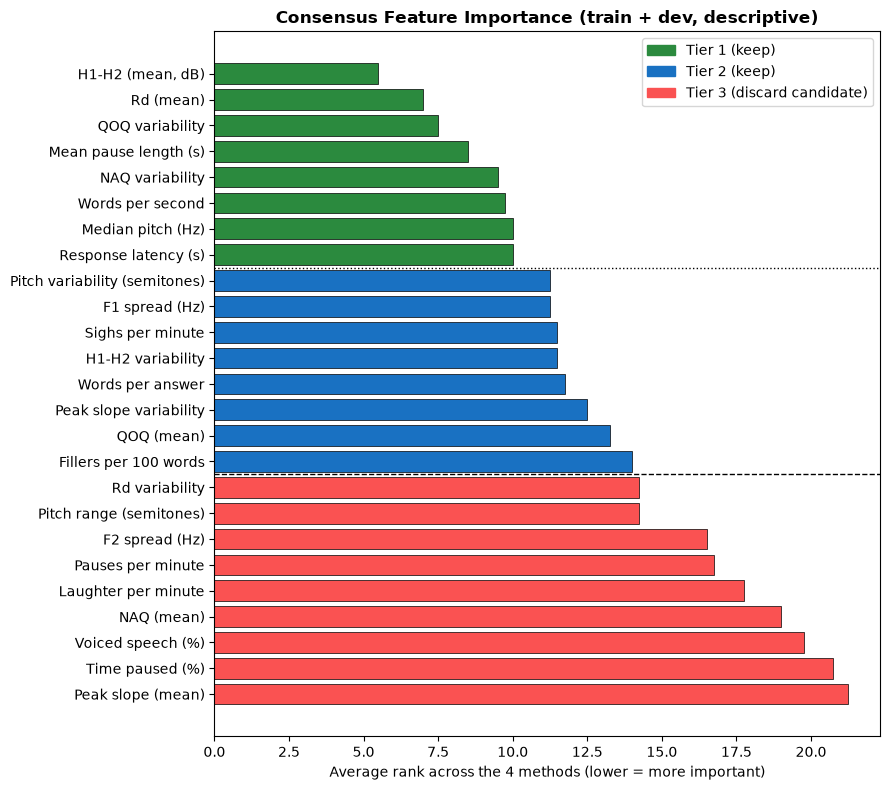

In [46]:
# Horizontal bar plot of the consensus ranking (shorter bar = more important)
from matplotlib.patches import Patch

TIER_COLOURS = {"Tier 1 (keep)": "#2b8a3e", "Tier 2 (keep)": "#1971c2", "Tier 3 (discard candidate)": "#fa5252"}
plot_df = imp_df.iloc[::-1]   # most important at the top

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh([LABELS.get(f, f) for f in plot_df.index], plot_df["Consensus_avg_rank"],
        color=[TIER_COLOURS[t] for t in plot_df["Tier"]], edgecolor="black", linewidth=0.5)
ax.axhline(8.5, color="black", linestyle="--", linewidth=1)    # between rank 16 and 17
ax.axhline(16.5, color="black", linestyle=":", linewidth=1)    # between rank 8 and 9
ax.set_xlabel("Average rank across the 4 methods (lower = more important)")
ax.set_title("Consensus Feature Importance (train + dev, descriptive)", fontweight="bold")
ax.legend(handles=[Patch(color=c, label=t) for t, c in TIER_COLOURS.items()], loc="upper right")
fig.tight_layout()
fig.savefig(RESULTS / "consensus_feature_importance.png", dpi=200)
plt.show()

### 5k. Does discarding features help? A pruning test without leakage

Now we test the mentor's directive directly: keep only the top-k features, and check whether cross-validated UAR improves.

**Avoiding leakage:** the ranking must never see the people it is evaluated on. So *inside every fold*:
1. Rank the features using only the 4 training folds (same 4 methods and consensus as 5j).
2. Keep the top k.
3. Train on the training folds using those k features, then predict the held-out fold.

This is called **nested** feature selection. Each fold can pick a slightly different top-k, and that is informative too: if the chosen features change a lot from fold to fold, the ranking is unstable.

- **Subsets:** all 25; top 16 (Tiers 1+2, i.e. discard Tier 3); top 12; top 8 (Tier 1); top 5.
- **Models:** Logistic Regression, SVM, Random Forest, XGBoost, and Gaussian Naive Bayes (the strongest model in 5e and 5h).
- **Repeated 3 times** with different fold splits → `mean ± std`. Takes a few minutes.

In [47]:
SUBSET_SIZES = [25, 16, 12, 8, 5]
PRUNE_MODELS = ["Logistic Regression", "SVM (RBF Kernel)", "Random Forest", "XGBoost", "Gaussian Naive Bayes"]

pruning_rows = []
chosen_top8 = []   # the top-8 features picked in each training fold, to check stability

for repeat in range(3):
    preds = {(k, m): np.zeros(len(pool), dtype=int) for k in SUBSET_SIZES for m in PRUNE_MODELS}
    for tr, te in StratifiedKFold(n_splits=5, shuffle=True, random_state=repeat).split(pool, strata):
        # 1. Rank features using the training folds only
        ranking = consensus_ranking(importance_scores(X_pool.iloc[tr], y_pool.iloc[tr], seed=repeat)).index.tolist()
        chosen_top8.append(ranking[:8])
        # 2-3. Keep the top k, train on the training folds, predict the held-out fold
        for k in SUBSET_SIZES:
            cols = ranking[:k]
            models = make_models(seed=repeat)
            for m in PRUNE_MODELS:
                pipe = make_pipeline_for(models[m]).fit(X_pool.iloc[tr][cols], y_pool.iloc[tr])
                preds[(k, m)][te] = pipe.predict(X_pool.iloc[te][cols])
    for (k, m), p in preds.items():
        pruning_rows.append({
            "repeat": repeat, "Num_Features": k, "Model": m,
            "UAR": balanced_accuracy_score(y_pool, p),
            "Macro_F1": f1_score(y_pool, p, average="macro", zero_division=0),
            "F1_Depressed": f1_score(y_pool, p, pos_label=1, zero_division=0),
        })
    print(f"repeat {repeat + 1} / 3 done")

pruning_df = pd.DataFrame(pruning_rows)
pruning_summary = (pruning_df.groupby(["Num_Features", "Model"])["UAR"].agg(["mean", "std"])
                   .unstack("Model").sort_index(ascending=False))
print("=== Nested feature-pruning test: cross-validated UAR (mean and std over 3 repeats) ===")
pruning_summary.round(3)

repeat 1 / 3 done


repeat 2 / 3 done


repeat 3 / 3 done
=== Nested feature-pruning test: cross-validated UAR (mean and std over 3 repeats) ===


mean                                    \
Model        Gaussian Naive Bayes Logistic Regression Random Forest   
Num_Features                                                          
25                          0.565               0.528         0.523   
16                          0.516               0.515         0.504   
12                          0.527               0.494         0.493   
8                           0.502               0.505         0.487   
5                           0.524               0.477         0.480   

                                                       std  \
Model        SVM (RBF Kernel) XGBoost Gaussian Naive Bayes   
Num_Features                                                 
25                      0.529   0.541                0.040   
16                      0.515   0.524                0.006   
12                      0.521   0.505                0.012   
8                       0.502   0.496                0.013   
5                       0.490   0.490                0.010   

                                                                         
Model        Logistic Regression Random Forest SVM (RBF Kernel) XGBoost  
Num_Features                                                             
25                         0.039         0.053            0.013   0.019  
16                         0.042         0.025            0.033   0.032  
12                         0.030         0.037            0.011   0.032  
8                          0.035         0.003            0.021   0.017  
5                          0.010         0.013            0.011   0.019

In [48]:
# How often did each feature make the top 8, across the 15 training folds (3 repeats x 5 folds)?
top8_counts = pd.Series([f for top in chosen_top8 for f in top]).value_counts()
print(f"Features chosen in the top 8 of all {len(chosen_top8)} folds:", list(top8_counts[top8_counts == len(chosen_top8)].index))
top8_counts.rename(f"times in top 8 (out of {len(chosen_top8)} folds)")

Features chosen in the top 8 of all 15 folds: []


mean_pause_s        14
qoq_sd              13
h1h2_mean            9
f1_sd_hz             9
f0_sd_st             8
median_latency_s     8
peakslope_sd         7
h1h2_sd              6
rd_sd                6
f0_median_hz         5
rd_mean              5
naq_sd               5
words_per_answer     4
fillers_per_100w     4
words_per_sec        4
laughter_per_min     2
pauses_per_min       2
f2_sd_hz             2
voiced_pct           2
qoq_mean             2
f0_range_st          1
naq_mean             1
pause_pct            1
Name: times in top 8 (out of 15 folds), dtype: int64

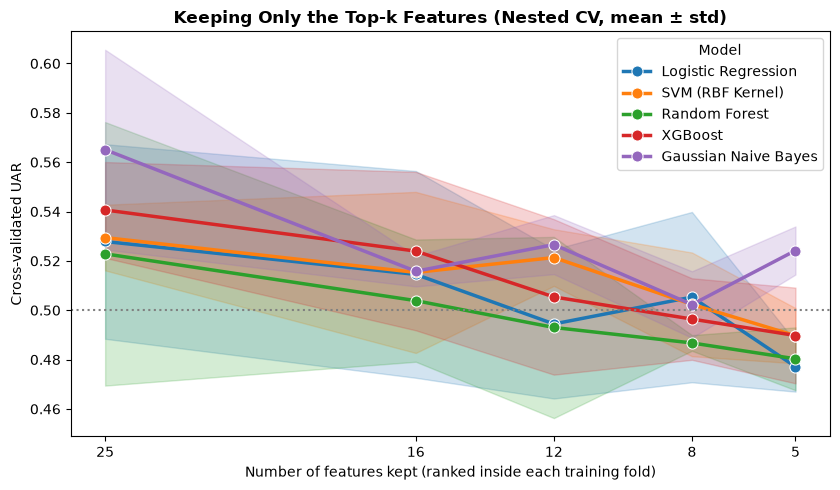

In [49]:
# Plot the pruning test: UAR vs. number of features kept (mean ± std over the 3 repeats)
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.lineplot(data=pruning_df, x="Num_Features", y="UAR", hue="Model", marker="o", linewidth=2.5,
             markersize=8, errorbar="sd", ax=ax)
ax.axhline(0.5, color="gray", linestyle=":", label="Chance")
ax.set_xticks(SUBSET_SIZES)
ax.set_title("Keeping Only the Top-k Features (Nested CV, mean ± std)", fontweight="bold")
ax.set_xlabel("Number of features kept (ranked inside each training fold)")
ax.set_ylabel("Cross-validated UAR")
ax.invert_xaxis()  # 25 down to 5
fig.tight_layout()
fig.savefig(RESULTS / "feature_pruning_ablation.png", dpi=200)
plt.show()

### 5k.2. Recursive Feature Elimination (RFE): how many features do we need?

The reference paper shared by our guide (Kumar & Muduli, *A multi-domain feature-based ensemble learning approach for cuffless blood pressure estimation*, Artificial Intelligence in Emergency Medicine, 2026) chooses its feature count with **Recursive Feature Elimination** (its Tables 3 and 4). We run the same test on our data.

**How RFE works:**
1. Train a model on all 25 features.
2. Drop the single least important feature (for logistic regression: the smallest |β|).
3. Retrain on the features that are left and repeat, until one feature remains.

The order in which features are dropped is a full ranking: the last feature standing is rank 1. Unlike 5j, which scores every feature once, RFE re-scores after every removal. So when two features carry the same information, dropping one makes the other look more important.

**Two deliberate differences from the paper:**
- **Speaker-independent and nested.** In the paper's dataset the same patient can appear in both training and test data (the authors say so), and the feature count is picked from the test error. Here RFE runs inside each training fold only, so the held-out people never influence the ranking, and each person is in exactly one fold.
- **Classification, not regression.** The paper predicts a number (blood pressure, scored by mean absolute error). We predict a class, so we report UAR.

**Setup:** inside each training fold, RFE ranks the features with logistic regression. We keep the top k (25, 20, 16, 14, 12, 10, 8, 5) and train 4 models on them: Logistic Regression, SVM, Random Forest and Gaussian Naive Bayes. Repeated 3 times with different fold splits, like 5k. Takes under a minute.

In [50]:
from sklearn.feature_selection import RFE

RFE_SIZES = [25, 20, 16, 14, 12, 10, 8, 5]
RFE_MODELS = ["Logistic Regression", "SVM (RBF Kernel)", "Random Forest", "Gaussian Naive Bayes"]


def rfe_order(X, y):
    """Feature names from most to least important, by RFE with logistic regression, learned from (X, y) only."""
    prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    rfe = RFE(LogisticRegression(class_weight="balanced", max_iter=1000), n_features_to_select=1, step=1)
    rfe.fit(prep.fit_transform(X), y)
    return [X.columns[i] for i in np.argsort(rfe.ranking_)]   # ranking_ = 1 for the last feature standing


rfe_rows = []
rfe_fold_orders = []   # the full RFE order from each training fold, to check stability

for repeat in range(3):
    preds = {(k, m): np.zeros(len(pool), dtype=int) for k in RFE_SIZES for m in RFE_MODELS}
    for tr, te in StratifiedKFold(n_splits=5, shuffle=True, random_state=repeat).split(pool, strata):
        # 1. RFE ranking from the training folds only
        order = rfe_order(X_pool.iloc[tr], y_pool.iloc[tr])
        rfe_fold_orders.append(order)
        # 2-3. Keep the top k, train on the training folds, predict the held-out fold
        for k in RFE_SIZES:
            cols = order[:k]
            models = make_models(seed=repeat)
            for m in RFE_MODELS:
                pipe = make_pipeline_for(models[m]).fit(X_pool.iloc[tr][cols], y_pool.iloc[tr])
                preds[(k, m)][te] = pipe.predict(X_pool.iloc[te][cols])
    for (k, m), p in preds.items():
        rfe_rows.append({
            "repeat": repeat, "Num_Features": k, "Model": m,
            "UAR": balanced_accuracy_score(y_pool, p),
            "F1_Depressed": f1_score(y_pool, p, pos_label=1, zero_division=0),
        })
    print(f"repeat {repeat + 1} / 3 done")

rfe_df = pd.DataFrame(rfe_rows)
rfe_summary = (rfe_df.groupby(["Num_Features", "Model"])["UAR"].agg(["mean", "std"])
               .unstack("Model").sort_index(ascending=False))
print("=== RFE sweep: cross-validated UAR (mean and std over 3 repeats) ===")
rfe_summary.round(3)

repeat 1 / 3 done


repeat 2 / 3 done


repeat 3 / 3 done
=== RFE sweep: cross-validated UAR (mean and std over 3 repeats) ===


mean                                    \
Model        Gaussian Naive Bayes Logistic Regression Random Forest   
Num_Features                                                          
25                          0.565               0.528         0.525   
20                          0.553               0.527         0.519   
16                          0.545               0.512         0.523   
14                          0.549               0.521         0.513   
12                          0.541               0.516         0.490   
10                          0.549               0.544         0.489   
8                           0.552               0.517         0.511   
5                           0.523               0.530         0.481   

                                               std                      \
Model        SVM (RBF Kernel) Gaussian Naive Bayes Logistic Regression   
Num_Features                                                             
25                      0.529                0.040               0.039   
20                      0.550                0.040               0.030   
16                      0.533                0.019               0.037   
14                      0.561                0.019               0.021   
12                      0.530                0.028               0.033   
10                      0.526                0.025               0.042   
8                       0.537                0.016               0.046   
5                       0.511                0.019               0.056   

                                             
Model        Random Forest SVM (RBF Kernel)  
Num_Features                                 
25                   0.038            0.013  
20                   0.047            0.012  
16                   0.062            0.029  
14                   0.032            0.016  
12                   0.040            0.023  
10                   0.042            0.014  
8                    0.047            0.024  
5                    0.004            0.025

The table below is our version of the paper's Table 4: which features RFE keeps. The first two columns rank on all 142 people (descriptive, like 5j). The last two show how stable that is across the 15 training folds: a feature that is really important should be near the top in most folds, not just once.

In [51]:
# Which features does RFE keep? Ranking on all 142 people (descriptive, like 5j) next to the per-fold rankings
full_order = rfe_order(X_pool, y_pool)
fold_ranks = pd.DataFrame([{f: order.index(f) + 1 for f in order} for order in rfe_fold_orders])

rfe_rank_table = pd.DataFrame({
    "Domain": ["timing" if f in TIMING_COLS else "voice" for f in full_order],
    "RFE rank (all 142)": range(1, len(full_order) + 1),
    "Kept in top 8 (all 142)": [r <= 8 for r in range(1, len(full_order) + 1)],
    "Median rank across folds": fold_ranks[full_order].median().to_numpy(),
    f"Times in top 8 (of {len(rfe_fold_orders)} folds)": [(fold_ranks[f] <= 8).sum() for f in full_order],
}, index=pd.Index(full_order, name="feature"))
rfe_rank_table

,Domain,RFE rank (all 142),Kept in top 8 (all 142),Median rank across folds,Times in top 8 (of 15 folds)
feature,,,,,
qoq_sd,voice,1,True,3.0,12
h1h2_mean,voice,2,True,4.0,13
f0_range_st,voice,3,True,3.0,12
f0_sd_st,voice,4,True,4.0,12
rd_mean,voice,5,True,5.0,14
median_latency_s,timing,6,True,7.0,10
peakslope_sd,voice,7,True,9.0,7
voiced_pct,voice,8,True,9.0,7
laughter_per_min,timing,9,False,10.0,5


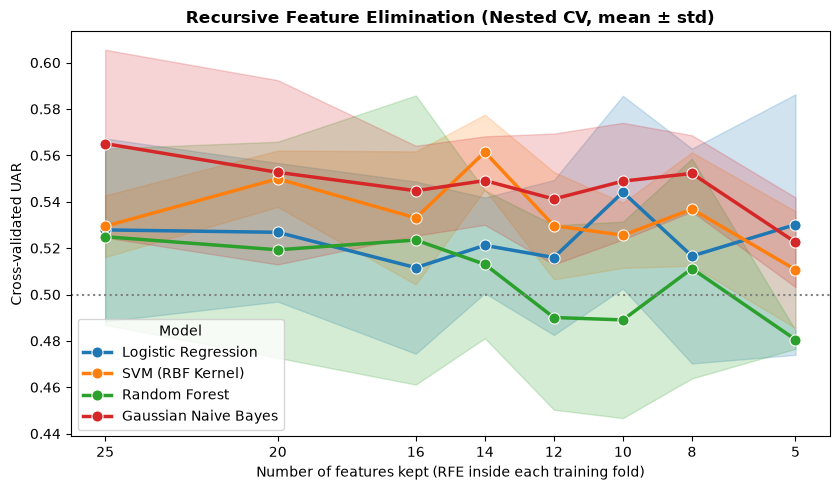

In [52]:
# Plot the RFE sweep: UAR vs. number of features kept (mean ± std over the 3 repeats)
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.lineplot(data=rfe_df, x="Num_Features", y="UAR", hue="Model", marker="o", linewidth=2.5,
             markersize=8, errorbar="sd", ax=ax)
ax.axhline(0.5, color="gray", linestyle=":", label="Chance")
ax.set_xticks(RFE_SIZES)
ax.set_title("Recursive Feature Elimination (Nested CV, mean ± std)", fontweight="bold")
ax.set_xlabel("Number of features kept (RFE inside each training fold)")
ax.set_ylabel("Cross-validated UAR")
ax.invert_xaxis()  # 25 down to 5
fig.tight_layout()
fig.savefig(RESULTS / "rfe_sweep.png", dpi=200)
plt.show()

**Reading the RFE results:**

- **RFE does not reliably beat all 25 features.** Gaussian Naive Bayes, the strongest model, is best with all 25 (UAR 0.565), and every smaller set is lower. Random Forest drops as features are removed (0.52 → 0.48 at 5 features).
- **Two models show small bumps.** SVM peaks at 14 features (0.561 vs. 0.529 with all 25), and logistic regression at 10 (0.544 vs. 0.528). Both bumps are about one to two standard deviations, and we're picking the best of 32 cells (8 sizes × 4 models) after seeing them all. The best cell of a noisy table is almost always optimistic, so we treat these as *hints*, not results. (The reference paper also settled on 14 features, but its gain from 16 to 14 was zero mean absolute error for SBP, so that choice was about using fewer features, not better accuracy.)
- **The RFE ranking is more stable than the importance ranking in 5k.** Five voice features make the top 8 in 12–14 of the 15 folds: `rd_mean`, `h1h2_mean`, `qoq_sd`, `f0_sd_st`, `f0_range_st`. Response latency (`median_latency_s`) is the only timing feature that's usually kept (10 of 15). So RFE with logistic regression mostly keeps **voice quality and pitch variability**.
- **But the two methods disagree on which features matter.** Mean pause length was in the 5k top 8 in 14 of 15 folds, yet only 3 of 15 here. Each method measures "importance" differently. Combined with point 1, this is why we keep all 25 features for now rather than committing to a subset.
- **`h1h2_mean` again ranks near the top**, and Step 4 showed it is mostly a gender difference. A high rank does not mean the feature measures depression.

### 5k.3. Other ways to reduce features

RFE and the importance ranking both *select* a subset of the original features. We also try three other common approaches:

- **Univariate filter (ANOVA F-test):** score each feature on its own by how far apart the two groups' means are, then keep the top k. Fast, but blind to redundancy: two near-copies of the same feature both get kept.
- **L1 (lasso) logistic regression:** a logistic regression with a penalty that pushes the weights of weak features to exactly zero. Features with a non-zero weight are kept. How many survive depends on the penalty strength, which we fix in advance (C = 0.1).
- **PCA (principal component analysis):** instead of choosing features, build k *new* ones, each a weighted mix of all 25, that together capture as much of the spread between people as possible. The reference paper uses PCA to rank its features (its Table 2). PCA never looks at the labels, though: the directions in which people differ most need not be the ones in which depressed and non-depressed people differ.

Each reducer sits **inside the pipeline**, between rescaling and the model. So `cross_val_predict` refits it on the training folds of every split, and there's no leakage without any extra code. Same 4 models, 3 repeats.

In [53]:
from sklearn.feature_selection import SelectKBest, f_classif, SelectFromModel
from sklearn.decomposition import PCA

# Each entry builds a fresh, unfitted reduction step
REDUCERS = {
    "none (all 25)": lambda: "passthrough",
    "ANOVA top-5": lambda: SelectKBest(f_classif, k=5),
    "ANOVA top-8": lambda: SelectKBest(f_classif, k=8),
    "ANOVA top-12": lambda: SelectKBest(f_classif, k=12),
    "L1-logistic (C=0.1)": lambda: SelectFromModel(LogisticRegression(penalty="l1", C=0.1, solver="liblinear",
                                                                       class_weight="balanced")),
    "PCA 3 components": lambda: PCA(n_components=3),
    "PCA 5 components": lambda: PCA(n_components=5),
    "PCA 8 components": lambda: PCA(n_components=8),
}

reduce_rows = []
for repeat in range(3):
    folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=repeat).split(pool, strata))
    for method, make_reducer in REDUCERS.items():
        for m in RFE_MODELS:
            # fill gaps -> rescale -> reduce -> model; cross_val_predict refits all four steps in every fold
            pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), make_reducer(),
                                 make_models(seed=repeat)[m])
            p = cross_val_predict(pipe, X_pool, y_pool, cv=folds)
            reduce_rows.append({"repeat": repeat, "Method": method, "Model": m,
                                "UAR": balanced_accuracy_score(y_pool, p)})
    print(f"repeat {repeat + 1} / 3 done")

reduce_df = pd.DataFrame(reduce_rows)
reduce_summary = reduce_df.groupby(["Method", "Model"], sort=False)["UAR"].mean().unstack("Model")
reduce_summary["Average over models"] = reduce_summary.mean(axis=1)
print("=== Other reduction methods: cross-validated UAR (mean over 3 repeats) ===")
reduce_summary.round(3)

C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio

C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio

C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio

repeat 1 / 3 done


... (10 outputs left out)

C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\kushw\.conda\envs\speech-dep\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio

repeat 3 / 3 done
=== Other reduction methods: cross-validated UAR (mean over 3 repeats) ===


Model,Logistic Regression,SVM (RBF Kernel),Random Forest,Gaussian Naive Bayes,Average over models
Method,,,,,
none (all 25),0.528,0.529,0.521,0.565,0.536
ANOVA top-5,0.565,0.561,0.489,0.576,0.548
ANOVA top-8,0.545,0.552,0.487,0.545,0.532
ANOVA top-12,0.527,0.571,0.525,0.560,0.546
L1-logistic (C=0.1),0.528,0.525,0.516,0.543,0.528
PCA 3 components,0.597,0.560,0.570,0.533,0.565
PCA 5 components,0.576,0.577,0.545,0.528,0.556
PCA 8 components,0.525,0.564,0.518,0.504,0.528


**Reading the table:**

- **The filters (ANOVA, L1) don't help on average.** ANOVA top-5 nudges Gaussian Naive Bayes from 0.565 to 0.576, which is well within the noise. L1 (0.528 on average) is no better than using all 25 features (0.536).
- **PCA with 3 components gives the highest average** (0.565 over the 4 models, vs. 0.536 with all 25), and the best single result in this section (logistic regression, 0.597). A plausible reason is that many of our 25 features are correlated (e.g. pitch spread and pitch range), so a few combined directions keep most of the information with less noise for linear models to overfit. Note that PCA makes Gaussian Naive Bayes *worse* (0.565 → 0.533).
- **Why we don't adopt PCA yet:** the gain is about 0.03, roughly one standard deviation, and it is the best of 32 method × model combinations chosen after seeing them all. **PCA-3 + logistic regression is recorded here as a candidate.** The fair test is the untouched `test` split at the End-Review, where the choice can no longer be tuned.

### 5l. Inference time (a first indicator for Phase 8)

How long does each model take to make a prediction once the 25 features exist? This was measured in 5e: the time to predict the 35 dev people in one batch, divided by 35, on this laptop's CPU.

Two cautions before linking this to a Raspberry Pi or Jetson Nano:
- It **excludes feature extraction** (reading the audio or COVAREP frames, computing pitch and voice quality), which takes far longer than the classifier itself.
- It was measured on a laptop, not on a Pi. A Pi's CPU is several times slower, so these numbers can't be carried over directly.

So this shows the classifiers themselves are cheap. It does not yet show that the full pipeline meets an edge latency budget.

The reference paper reports prediction time **including** feature extraction (0.129 s per sample on Google Colab, 0.463 s on its PYNQ-Z2 edge board). The second cell below makes a first step in that direction: it times our feature extraction on this laptop. One caveat remains: the COVAREP frames themselves were computed by the dataset authors. We only read and summarise them, so computing COVAREP from raw audio on the device would add more time.

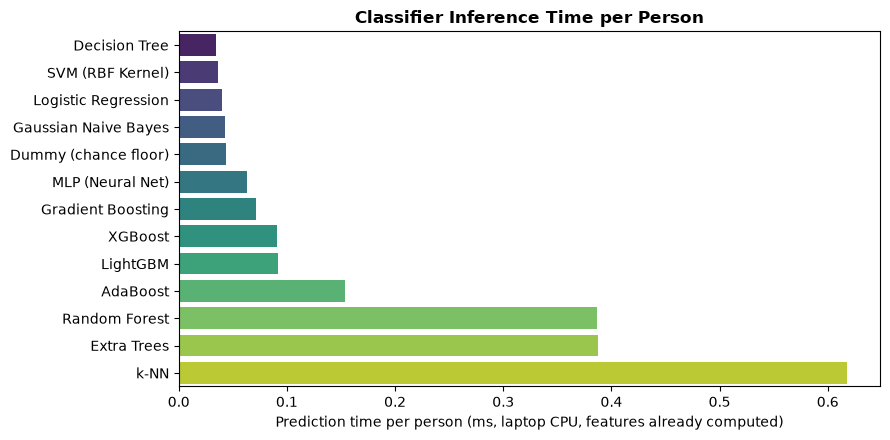

In [54]:
# Inference time per person (from the dev run in 5e)
fig, ax = plt.subplots(figsize=(9, 4.5))
lat_df = dev_table.reset_index().sort_values(by="latency_ms")
sns.barplot(data=lat_df, x="latency_ms", y="model", hue="model", palette="viridis", legend=False, ax=ax)
ax.set_xlabel("Prediction time per person (ms, laptop CPU, features already computed)")
ax.set_ylabel("")
ax.set_title("Classifier Inference Time per Person", fontweight="bold")
fig.tight_layout()
fig.savefig(RESULTS / "inference_latency_benchmark.png", dpi=200)
plt.show()

In [55]:
# Feature-extraction time per participant on this laptop, averaged over 5 participants
sample_ids = features["Participant_ID"].iloc[:5]
t0 = time.perf_counter()
for sid in sample_ids:
    timing_features(sid)
t1 = time.perf_counter()
for sid in sample_ids:
    covarep_features(sid)
t2 = time.perf_counter()
print(f"timing features (transcript):            {(t1 - t0) / len(sample_ids):.2f} s per participant")
print(f"voice features (COVAREP + formant files): {(t2 - t1) / len(sample_ids):.2f} s per participant")

timing features (transcript):            0.01 s per participant
voice features (COVAREP + formant files): 0.32 s per participant


### 5m. Comparison with the published baseline on the same dev split

The reference paper ends with a comparison against earlier methods (its Table 6). Our natural comparison is the **official AVEC 2016 baseline** (Valstar et al., *AVEC 2016: Depression, Mood, and Emotion Recognition Workshop and Challenge*, 2016, Table 3). It reports F1 for each class on **exactly this dev split** (the same 35 people).

Their audio baseline also uses COVAREP features, but differently: a linear SVM classifies every 10 ms frame, and each interview's label is the majority vote of its frames. We summarise each interview into 25 numbers first and classify once per person. The video baseline uses facial features, a different modality, and is listed for context only.

In [56]:
# Official AVEC 2016 baseline on the same dev split (Valstar et al., 2016, Table 3), next to our dev results from 5e
published = pd.DataFrame([
    {"Method": "AVEC 2016 baseline: audio (COVAREP, linear SVM)",
     "F1 depressed": 0.462, "F1 not depressed": 0.682, "Precision depressed": 0.316, "Recall depressed": 0.857},
    {"Method": "AVEC 2016 baseline: video (facial features)",
     "F1 depressed": 0.500, "F1 not depressed": 0.896, "Precision depressed": 0.600, "Recall depressed": 0.428},
])

ours = dev_table.loc[["Gaussian Naive Bayes", "Logistic Regression", "Dummy (chance floor)"],
                     ["f1_depressed", "f1_not", "precision_depressed", "recall_depressed"]]
ours.columns = ["F1 depressed", "F1 not depressed", "Precision depressed", "Recall depressed"]
ours.index = "Ours (audio, 25 features): " + ours.index

comparison_table = pd.concat([published.set_index("Method"), ours])
comparison_table.index.name = "Method"
comparison_table.round(3)

,F1 depressed,F1 not depressed,Precision depressed,Recall depressed
Method,,,,
"AVEC 2016 baseline: audio (COVAREP, linear SVM)",0.462,0.682,0.316,0.857
AVEC 2016 baseline: video (facial features),0.500,0.896,0.600,0.428
"Ours (audio, 25 features): Gaussian Naive Bayes",0.560,0.756,0.538,0.583
"Ours (audio, 25 features): Logistic Regression",0.467,0.600,0.389,0.583
"Ours (audio, 25 features): Dummy (chance floor)",0.000,0.793,0.000,0.000


**Reading the table:**

- **Our Gaussian Naive Bayes beats the official AVEC 2016 audio baseline on both classes**: F1 0.56 vs. 0.46 for depressed, 0.76 vs. 0.68 for not depressed. Its depressed-class precision is also much higher (0.54 vs. 0.32): the AVEC baseline catches more depressed people (recall 0.86) by flagging far too many healthy people.
- **Logistic regression roughly matches the AVEC audio baseline** for depressed-class F1 (0.47 vs. 0.46).
- **The video baseline is stronger on the non-depressed class** (F1 0.90), but it uses a different modality (the face), so it is context, not a competitor.
- **Caveats:** this is the 35-person dev set, where every model's bootstrap interval includes chance (5g), and AVEC reports a single run. Our steadier estimate is the cross-validated UAR of 0.57 (5h). So the honest claim is that our session-level audio baseline is **on par with or slightly better than** the official audio baseline, not that it is good in absolute terms.

In [57]:
# Save all tables
dev_table.to_csv(RESULTS / "expanded_10models_dev.csv")
cv_table.to_csv(RESULTS / "expanded_10models_cv.csv")
imp_df.to_csv(RESULTS / "consensus_feature_importance.csv")
pruning_df.to_csv(RESULTS / "feature_pruning_results.csv", index=False)
pruning_summary.to_csv(RESULTS / "feature_pruning_summary.csv")
top8_counts.to_csv(RESULTS / "feature_pruning_top8_stability.csv")
boot_table.to_csv(RESULTS / "expanded_dev_bootstrap.csv")
seed_spread.to_csv(RESULTS / "expanded_dev_seed_spread.csv")
group_table.to_csv(RESULTS / "expanded_feature_groups_cv.csv")
rfe_df.to_csv(RESULTS / "rfe_sweep_results.csv", index=False)
rfe_summary.to_csv(RESULTS / "rfe_sweep_summary.csv")
rfe_rank_table.to_csv(RESULTS / "rfe_feature_ranks.csv")
reduce_summary.to_csv(RESULTS / "other_reduction_methods_cv.csv")
comparison_table.to_csv(RESULTS / "comparison_with_avec2016.csv")
print("Saved all Step 5 tables and figures to:", RESULTS)

Saved all Step 5 tables and figures to: ..\results\mid_review


### What Step 5 tells us (for the slides)

Check that this matches your tables:

1. **Baseline performance is modest, and the models are close to each other.** In 5-fold cross-validation on 142 people (5h), the 12 models reach a UAR between about **0.48 and 0.57**, and most sit at 0.50–0.55, just above chance. Gaussian Naive Bayes is highest in both evaluations: CV UAR **0.57 ± 0.03** (ROC-AUC 0.62), dev UAR 0.66. The **CV number is the main estimate**. **Against the official AVEC 2016 audio baseline on the same dev split (5m)**, Naive Bayes scores higher F1 on both classes (depressed 0.56 vs. 0.46, not depressed 0.76 vs. 0.68; Valstar et al., 2016, Table 3), and logistic regression roughly matches it (0.47).
2. **The dev numbers are very uncertain (5g).** Every model's bootstrap 95% interval includes chance, even Naive Bayes's (0.49 to 0.83), and the random seed alone moves some models' dev UAR by up to 0.17. So we **can't rank the models from the dev set**; they're effectively tied.
3. **The accuracy trap is real (5f).** The dummy scores 65.7% accuracy on dev while catching **zero** depressed people (UAR 0.50). Logistic regression and Naive Bayes both catch 7 of the 12 depressed dev people; Naive Bayes wins on UAR because it raises 6 false alarms instead of 11. Extra Trees, k-NN and Gradient Boosting reach 57–66% dev accuracy but catch at most 1 in 6 depressed people.
4. **Combining feature groups did not help at this level (5i).** All 25 features together was not the best set for any of the 12 models; on average, timing only (0.54) and voice only (0.54) both beat all 25 (0.52). Tree-based models tend to prefer timing, linear/kernel/probabilistic models prefer voice. So the guide's advice to combine groups is **not supported yet** with whole-interview averages on 142 people. We'll test it again with segment-level features in the GNN.
5. **Feature importance: the methods disagree (5j).** The consensus ranking puts H1-H2 (mean), Rd (mean), QOQ variability, mean pause length, NAQ variability, words per second, median pitch and response latency in the top 8, but the individual methods disagree strongly (e.g. sigh rate is 2nd for XGBoost and last for Random Forest). Two of the top features, **H1-H2 (mean) and median pitch, are the ones Step 4 showed are mostly gender differences**, so the models may partly be detecting sex rather than depression. This is direct evidence for Objective 3.
6. **Discarding features by importance rank did not help (5k).** In the leak-free nested test, keeping all 25 features gives the best UAR for every one of the 5 models, and keeping only the top 8 drops them to chance (0.49–0.51). No feature made the top 8 in all 15 training folds. An earlier version of the test ranked the features on all 142 people *before* cross-validating, and it suggested the top 8 lifted logistic regression's UAR to about 0.60. That gain disappears once the ranking can't see the people being predicted, which is a concrete example of how leakage inflates results. **Answer to the mentor's question:** with 142 people, the importance ranking is too noisy to choose features reliably. Point 4 suggests a smaller, *theory-driven* feature set can do as well as all 25, so the next step is to choose feature groups by hypothesis, not by an importance ranking. **RFE and other reduction methods (5k.2–5k.3) give the same answer.** RFE (the method in the reference paper) never beats all 25 features for Naive Bayes, and its small bumps for SVM (14 features) and logistic regression (10) are within the noise. PCA with 3 components gives the best average (0.565 vs. 0.536), about one standard deviation, so it is recorded as a candidate for the End-Review test split, not adopted. RFE's most stable picks are voice quality and pitch variability plus response latency.
7. **The classifiers are cheap to run (5l).** Every model predicts in under 1 ms per person on a laptop CPU. Turning one participant's files into the 25 features takes about 0.3 s on the laptop, almost all of it reading the COVAREP file (5l); the reference paper reports 0.46 s end to end on its edge board. That still excludes computing COVAREP from raw audio, which must be measured on the Pi / Jetson in Phase 8.
8. **Why a weak baseline is still a useful result.** Whole-interview averages compress each interview (median about 14 minutes, of which about 7 minutes is the participant speaking) into one number per feature, discarding *when* things happen. Step 4 showed a real signal (response latency), but averaging it into one number per person dilutes it. Our proposed GNN models the interview as a sequence of 3-second speech segments connected over time, which is exactly the information this baseline throws away. **The target: clearly beat CV UAR ≈ 0.57 under the same cross-validation.**

### Before the presentation, make sure you can explain:

- Why we train on `train`, evaluate on `dev`, and never touch `test` yet.
- What the pipeline does, and why the gap-filling and rescaling must learn from training data only.
- Why 7 models weight depressed people more heavily, why the other 5 can't, and what that does to their depressed recall.
- How to read a confusion matrix, why the dummy has ~66% accuracy but is useless, and why UAR is the main metric.
- What the bootstrap interval means, and why it is so wide with 35 dev people.
- Why the cross-validation number (Naive Bayes 0.57) is more trustworthy than the dev number (0.66).
- Why adding more features can make a model worse when there are only 142 people.
- What each of the 4 importance methods measures, why permutation importance must be scored on held-out people, and why we average ranks instead of scores.
- What nested feature selection is, and why the leaky version gave a result that looked better than it really was.
- Why the inference times here are not the full edge-deployment latency.
- How RFE works, and why ours runs inside each training fold while the reference paper picked its feature count from test error.
- The difference between *selecting* features (importance pruning, RFE, ANOVA, L1) and *combining* them (PCA), and why PCA ignores the labels.
- Why the best cell of a big results table is optimistic, and why that means PCA-3 is a candidate for the test split, not a result.
- What the AVEC 2016 audio baseline did differently (frame-level linear SVM + majority vote) and why our comparison uses F1 per class.